# European Airport Delays: Where Arrival ATFM Delays Build Up

**Author:** Boualem Pereira · [GitHub](https://github.com/BoualemP)

## 1. Overview

**Question:** where and why do airport arrival delays build up in Europe, and how do Lisbon (LPPT), Porto (LPPR) and Faro (LPFR) compare with other airports?

**ATFM delay** is the delay imposed on a flight by air traffic flow management because of a capacity constraint at its destination airport. It is not total flight punctuality.

**Datasets** (source: EUROCONTROL Aviation Intelligence Portal, https://ansperformance.eu/csv/):

| Dataset | Files | Role in this project |
|---|---|---|
| Airport Arrival ATFM Delays | `apt_dly_<YYYY>.csv.bz2`, 2014-2026 | Main dataset: daily arrivals, ATFM delay minutes (total and by delay code) and arrivals with ATFM delay per airport |
| Airport Traffic | `airport_traffic_<YYYY>.csv`, 2016-2026 | Traffic context (arrivals and departures) |

The data is downloaded from EUROCONTROL at run time and is not redistributed.

In this project, "Europe" and "Europe-wide" mean all airports reported by EUROCONTROL, which include some outside geographic Europe; the 42 countries are listed in section 3.9.



## 2. Setup

In [1]:
import bz2
import calendar
import codecs
from collections import Counter
import csv
import io
import json
import warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import pandas as pd
import requests

warnings.simplefilter("error")  # treat warnings as errors
warnings.filterwarnings("ignore", module="ipykernel")  # Jupyter kernel internals, not this analysis
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 400)
pd.set_option("display.max_colwidth", None)

# Data source and local cache
BASE_URL = "https://www.eurocontrol.int/performance/data/download/csv"
DATA_DIR = Path("data")
MANIFEST_PATH = DATA_DIR / "manifest.json"  # retrieval date and server metadata per file
REFRESH = False  # True: download every file again, ignoring the local cache

# Files to download (pattern and years as listed on https://ansperformance.eu/csv/)
DELAY_FILE = "apt_dly_{year}.csv.bz2"
DELAY_YEARS = range(2014, 2027)
TRAFFIC_FILE = "airport_traffic_{year}.csv"
TRAFFIC_YEARS = range(2016, 2027)

# Delay columns (names from the dataset reference page, seen in section 3.3)
DELAY_CODES = ["A", "C", "D", "E", "G", "I", "M", "N", "O", "P", "R", "S", "T", "V", "W", "NA"]
DELAY_TOTAL = "DLY_APT_ARR_1"
DELAY_CODE_COLUMNS = [f"DLY_APT_ARR_{code}_1" for code in DELAY_CODES]
# Delay codes as listed on https://ansperformance.eu/reference/dataset/airport-arrival-atfm-delay/
# (code: column label on the page, "Reason Group" on the page)
DELAY_CODE_REFERENCE = {
    "A": ("A - Accident/Incident - AD", "AD Disruptions"),
    "C": ("C - ATC Capacity - AD", "AD Capacity (ATC)"),
    "D": ("D - De-icing - AD", "AD Weather"),
    "E": ("E - Equipment (non-ATC) - AD", "AD Disruptions"),
    "G": ("G - Aerodrome Capacity - AD", "AD Capacity"),
    "I": ("I - Industrial Action (ATC) - AD", "AD Disruptions (ATC)"),
    "M": ("M - Airspace Management - AD", "AD Capacity"),
    "N": ("N - Industrial Action (non-ATC) - AD", "AD Disruptions"),
    "O": ("O - Other - AD", "AD Disruptions"),
    "P": ("P - Special Event - AD", "AD Events"),
    "R": ("R - ATC Routeing - AD", "AD Capacity"),
    "S": ("S - ATC Staffing - AD", "AD Staffing (ATC)"),
    "T": ("T - Equipment (ATC) - AD", "AD Disruptions (ATC)"),
    "V": ("V - Environmental Issues - AD", "AD Capacity"),
    "W": ("W - Weather - AD", "AD Weather"),
    "NA": ("NA - Not specified - AD", "AD Disruptions"),
}
DELAYED_ARRIVAL_COLUMNS = ["FLT_ARR_1_DLY", "FLT_ARR_1_DLY_15"]
DELAY_VALUE_COLUMNS = [DELAY_TOTAL, *DELAY_CODE_COLUMNS, *DELAYED_ARRIVAL_COLUMNS]

# Charts
SOURCE_NOTE = "Source: EUROCONTROL"
COLOR_FULL_YEAR = "#2a78d6"  # series 1
COLOR_SAME_MONTHS = "#eb6834"  # series 2
COLOR_MUTED = "#52514e"
COLOR_GRID = "#e4e3df"
SEQUENTIAL_BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]  # light to dark
LOW_TRAFFIC_YEARS = [2020, 2021]  # years with a traffic drop, see section 5.1
FOCUS_AIRPORTS = ["LPPT", "LPPR", "LPFR"]  # Lisbon, Porto, Faro
CANDIDATE_THRESHOLDS = [5_000, 10_000, 20_000, 50_000]  # arrivals per year, compared in section 5.3
MIN_ARRIVALS_RANKING = 20_000  # arrivals per year for airport rankings, chosen in section 5.3
TOP_N = 15
# Reason groups in a fixed order, each with a fixed categorical colour (validated palette, slots 1-7)
GROUP_ORDER = ["Capacity", "Weather", "Capacity (ATC)", "Staffing (ATC)", "Disruptions (ATC)",
               "Disruptions", "Events"]
GROUP_COLORS = dict(zip(GROUP_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]))
FEW_MINUTES = 1_000  # below this yearly total, an airport's cause shares rest on few minutes (section 5.4)
PEERS_EACH_SIDE = 5  # traffic peers: 5 airports above and 5 below in arrivals (section 5.5)
COLOR_OTHER = "#a3a29d"  # neutral grey for 'all other causes'
ATFM_CALCULATION_CHANGE = pd.Timestamp("2016-04-04")  # first v2 date, see section 3.7
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": COLOR_GRID,
    "axes.grid": True, "axes.axisbelow": True, "axes.grid.axis": "y", "grid.color": COLOR_GRID, "grid.linewidth": 0.8,
    "axes.labelcolor": COLOR_MUTED, "xtick.color": COLOR_MUTED, "ytick.color": COLOR_MUTED,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

print("pandas", pd.__version__)

pandas 3.1.1


### Functions: data collection

In [2]:
# Read the local manifest of downloaded files (empty if none yet).
def load_manifest():
    if MANIFEST_PATH.exists():
        return json.loads(MANIFEST_PATH.read_text())
    return {}


# Download one file into DATA_DIR unless it is cached; record retrieval date and server Last-Modified.
def download_file(file_name, manifest, refresh=REFRESH):
    path = DATA_DIR / file_name
    if path.exists() and file_name in manifest and not refresh:
        return path
    url = f"{BASE_URL}/{file_name}"
    response = requests.get(url, timeout=120)
    if response.status_code != 200:
        raise RuntimeError(f"{url} returned HTTP {response.status_code}; check https://ansperformance.eu/csv/")
    tmp_path = path.with_suffix(path.suffix + ".part")
    tmp_path.write_bytes(response.content)
    tmp_path.replace(path)
    manifest[file_name] = {
        "url": url,
        "retrieved_utc": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M"),
        "server_last_modified": response.headers.get("Last-Modified", ""),
    }
    return path


# Download (or reuse) one dataset for all years; return a table of the files as received.
def download_dataset(pattern, years, refresh=REFRESH):
    DATA_DIR.mkdir(exist_ok=True)
    manifest = load_manifest()
    rows = []
    for year in years:
        file_name = pattern.format(year=year)
        path = download_file(file_name, manifest, refresh)
        rows.append({
            "year": year,
            "file": file_name,
            "size_kb": round(path.stat().st_size / 1024, 1),
            **{k: v for k, v in manifest[file_name].items() if k != "url"},
        })
    MANIFEST_PATH.write_text(json.dumps(manifest, indent=2))
    return pd.DataFrame(rows)

### Functions: reading and inspection

In [3]:
# Decode bytes that are not valid UTF-8 as Latin-1, one byte at a time (see section 3.2).
def _latin1_fallback(error):
    return error.object[error.start:error.end].decode("latin-1"), error.end


codecs.register_error("latin1_fallback", _latin1_fallback)


# Raw bytes of a downloaded file (bz2 files are decompressed).
def read_bytes(file_name):
    path = DATA_DIR / file_name
    return bz2.open(path).read() if path.suffix == ".bz2" else path.read_bytes()


# Check whether a file decodes as UTF-8; report the first invalid byte and its context.
def check_utf8(file_name):
    raw = read_bytes(file_name)
    try:
        raw.decode("utf-8")
        return {"file": file_name, "utf8_valid": True, "first_invalid_byte": None, "context": ""}
    except UnicodeDecodeError as error:
        context = raw[max(0, error.start - 40):error.end + 10]
        return {"file": file_name, "utf8_valid": False, "first_invalid_byte": error.start, "context": repr(context)}


# Count the field values that are not valid UTF-8, by column (see section 3.2).
def invalid_utf8_by_column(file_name):
    text = read_bytes(file_name).decode("latin-1")  # one character per byte, so the bytes can be recovered
    reader = csv.reader(io.StringIO(text))
    header = next(reader)
    counts = Counter()
    for row in reader:
        for column, value in zip(header, row):
            raw = value.encode("latin-1")
            try:
                raw.decode("utf-8")
            except UnicodeDecodeError:
                counts[(column, repr(raw), raw.decode("utf-8", errors="latin1_fallback"))] += 1
    return pd.DataFrame(
        [(file_name, *key, n) for key, n in counts.items()],
        columns=["file", "column", "raw_bytes", "read_as", "rows"],
    )


# File content as text: UTF-8, with Latin-1 only for invalid bytes (see section 3.2).
def read_text(file_name):
    return read_bytes(file_name).decode("utf-8", errors="latin1_fallback")


# Return the first n lines of a raw file as text (nothing is parsed).
def read_raw_lines(file_name, n=3):
    return read_text(file_name).splitlines()[:n]


# Read every yearly file with pandas defaults (no type conversion); return {year: DataFrame}.
def read_raw_dataset(pattern, years):
    return {year: pd.read_csv(io.StringIO(read_text(pattern.format(year=year)))) for year in years}


# Table of which columns appear in which yearly file, in order of first appearance.
def columns_by_year(frames):
    all_columns = list(dict.fromkeys(c for df in frames.values() for c in df.columns))
    return pd.DataFrame(
        {year: ["x" if c in df.columns else "" for c in all_columns] for year, df in frames.items()},
        index=pd.Index(all_columns, name="column"),
    )


# Data type, missing values and distinct values for each column of a DataFrame.
def column_summary(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2),
        "distinct": df.nunique(),
    })

### Functions: raw data checks

In [4]:
# Rows where all, some or none of the delay value columns are missing, and rows with a zero total, by group (see section 3.6).
def missing_delay_values(df, by):
    missing = df[DELAY_VALUE_COLUMNS].isna()
    flags = pd.DataFrame({
        "rows": 1,
        "all_missing": missing.all(axis=1),
        "partly_missing": missing.any(axis=1) & ~missing.all(axis=1),
        "total_zero": df[DELAY_TOTAL].eq(0),
        "total_positive": df[DELAY_TOTAL].gt(0),
    })
    return flags.groupby([df[c] for c in by]).sum()


# First and last date, rows and years for each value of a column (see section 3.7).
def value_periods(df, column):
    return df.groupby(column).agg(
        first_date=("FLT_DATE", "min"),
        last_date=("FLT_DATE", "max"),
        rows=("FLT_DATE", "size"),
        years=("YEAR", lambda s: sorted(s.unique().tolist())),
    )


# Rows whose key columns appear more than once.
def duplicated_keys(df, keys):
    return df[df.duplicated(keys, keep=False)].sort_values(keys)


# Number of rows failing each arithmetic consistency rule (see section 3.8).
def consistency_checks(df):
    code_sum = df[DELAY_CODE_COLUMNS].sum(axis=1, min_count=1)
    has_values = df[DELAY_TOTAL].notna()
    checks = {
        "sum of code minutes != total minutes": has_values & (code_sum - df[DELAY_TOTAL]).abs().gt(1e-6),
        "arrivals with ATFM delay over 15 min > arrivals with ATFM delay": df["FLT_ARR_1_DLY_15"] > df["FLT_ARR_1_DLY"],
        "arrivals with ATFM delay > arrivals": df["FLT_ARR_1_DLY"] > df["FLT_ARR_1"],
        "ATFM delay minutes > 0 but no arrivals with ATFM delay": df[DELAY_TOTAL].gt(0) & df["FLT_ARR_1_DLY"].eq(0),
        "arrivals with ATFM delay > 0 but no ATFM delay minutes": df["FLT_ARR_1_DLY"].gt(0) & df[DELAY_TOTAL].eq(0),
        "negative value (any numeric column)": (df[["FLT_ARR_1", *DELAY_VALUE_COLUMNS]] < 0).any(axis=1),
        "zero arrivals": df["FLT_ARR_1"].eq(0),
        "non-integer value (any numeric column)": (df[["FLT_ARR_1", *DELAY_VALUE_COLUMNS]] % 1).gt(0).any(axis=1),
    }
    return pd.DataFrame({"rows": {name: int(mask.sum()) for name, mask in checks.items()}})


# Airports whose name or country changes within a year or across years (see section 3.9).
def airport_label_changes(df):
    labels = df.groupby(["APT_ICAO", "APT_NAME", "STATE_NAME"]).agg(
        first_year=("YEAR", "min"), last_year=("YEAR", "max"), rows=("YEAR", "size")
    ).reset_index()
    changing = labels["APT_ICAO"].duplicated(keep=False)
    return labels[changing].sort_values(["APT_ICAO", "first_year"])


# Per year: airports reported, airports new or gone versus the previous year, airports without every date (see section 3.9).
def airport_coverage_by_year(df):
    days = df.groupby(["YEAR", "APT_ICAO"]).size().unstack("YEAR")
    dates_in_year = df.groupby("YEAR")["FLT_DATE"].nunique()
    present = days.notna()
    return pd.DataFrame({
        "airports": present.sum(),
        "new": (present & ~present.shift(1, axis=1, fill_value=False)).sum(),
        "gone": (~present & present.shift(1, axis=1, fill_value=False)).sum(),
        "not_every_date": (days.lt(dates_in_year, axis=1) & present).sum(),
    }).rename_axis("year")


# Days reported and days missing per airport over the whole period (see section 3.9).
def airport_days(df):
    all_dates = df["FLT_DATE"].nunique()
    out = df.groupby("APT_ICAO").agg(
        name=("APT_NAME", "last"), state=("STATE_NAME", "last"),
        first_date=("FLT_DATE", "min"), last_date=("FLT_DATE", "max"), days=("FLT_DATE", "nunique"),
    )
    out["days_missing"] = all_dates - out["days"]
    return out.sort_values(["first_date", "last_date"])


# Number of airports by band of missing days.
def days_missing_bands(days):
    bands = pd.cut(days["days_missing"], bins=[-1, 0, 10, 100, 1000, float("inf")],
                   labels=["0", "1-10", "11-100", "101-1000", "over 1000"])
    return bands.value_counts(sort=False).rename_axis("days_missing").to_frame("airports")


# Rows with more arrivals with ATFM delay than arrivals (see section 3.10).
def atfm_delay_count_above_arrivals(df):
    columns = ["FLT_DATE", "APT_ICAO", "APT_NAME", "FLT_ARR_1", "FLT_ARR_1_DLY", "FLT_ARR_1_DLY_15", DELAY_TOTAL]
    return df.loc[df["FLT_ARR_1_DLY"] > df["FLT_ARR_1"], columns].sort_values("FLT_DATE")


# Rows with zero arrivals: count, airports and rows with delay minutes, by year (see section 3.10).
def zero_arrivals_by_year(df):
    zero = df[df["FLT_ARR_1"].eq(0)]
    return zero.groupby("YEAR").agg(
        rows=("APT_ICAO", "size"),
        airports=("APT_ICAO", "nunique"),
        rows_with_delay_minutes=(DELAY_TOTAL, lambda s: int(s.gt(0).sum())),
    )


# Airports with the most zero-arrival rows.
def zero_arrivals_by_airport(df, n=15):
    zero = df[df["FLT_ARR_1"].eq(0)]
    out = zero.groupby(["APT_ICAO", "APT_NAME"]).agg(zero_arrival_rows=("FLT_DATE", "size"))
    out["share_of_airport_rows_pct"] = (out["zero_arrival_rows"] / df.groupby("APT_ICAO").size()
                                         .reindex(out.index.get_level_values(0)).to_numpy() * 100).round(1)
    return out.sort_values("zero_arrival_rows", ascending=False).head(n)


# Dates with no row for an airport, between its first and last reported date (see section 3.12).
def missing_airport_days(df):
    day = df["FLT_DATE"].str[:10]  # date part only: the two datasets write dates differently (3.3, 3.11)
    all_dates = pd.Index(sorted(day.unique()))
    rows = []
    for icao, days in day.groupby(df["APT_ICAO"]):
        span = all_dates[(all_dates >= days.min()) & (all_dates <= days.max())]
        rows += [(icao, d) for d in span.difference(pd.Index(days))]
    return pd.DataFrame(rows, columns=["APT_ICAO", "date"])


# Look up missing airport-days in the traffic data: is there a traffic row, and how many arrivals (see section 3.12).
def match_in_traffic(missing, traffic):
    lookup = traffic.assign(date=traffic["FLT_DATE"].str[:10])[["APT_ICAO", "date", "FLT_ARR_1"]]
    out = missing.merge(lookup, on=["APT_ICAO", "date"], how="left")
    out["traffic_period"] = out["date"] >= traffic["FLT_DATE"].min()[:10]
    return out.rename(columns={"FLT_ARR_1": "traffic_arrivals"})


# Summary of the traffic lookup: missing days outside/inside the traffic period, found or not, arrivals.
def traffic_match_summary(matched):
    inside = matched[matched["traffic_period"]]
    found = inside[inside["traffic_arrivals"].notna()]
    return pd.Series({
        "missing airport-days": len(matched),
        "before the traffic period": int((~matched["traffic_period"]).sum()),
        "in the traffic period": len(inside),
        "  no traffic row either": int(inside["traffic_arrivals"].isna().sum()),
        "  traffic row, 0 arrivals": int(found["traffic_arrivals"].eq(0).sum()),
        "  traffic row, 1+ arrivals": int(found["traffic_arrivals"].gt(0).sum()),
        "  max traffic arrivals on a missing day": found["traffic_arrivals"].max() if len(found) else pd.NA,
    }, dtype="Int64").to_frame("value")

# Arrivals in rows where every delay value column is missing, against all rows (see section 3.6).
def arrivals_where_delay_missing(df):
    all_missing = df[DELAY_VALUE_COLUMNS].isna().all(axis=1)
    groups = {"delay values missing": df.loc[all_missing, "FLT_ARR_1"], "all rows": df["FLT_ARR_1"]}
    return pd.DataFrame.from_dict({
        name: {"rows": len(s), "FLT_ARR_1 missing": int(s.isna().sum()), "FLT_ARR_1 = 0": int(s.eq(0).sum()),
               "min": s.min(), "median": s.median(), "max": s.max()}
        for name, s in groups.items()
    }, orient="index")


# Europe-wide ATFM metrics from sums over all rows (missing delay values count as 0).
def europe_metrics(df):
    arrivals = df["FLT_ARR_1"].sum()
    return pd.Series({
        "arrivals": arrivals,
        "delay_min_per_arrival": df[DELAY_TOTAL].sum() / arrivals,
        "arr_with_atfm_delay_pct": df["FLT_ARR_1_DLY"].sum() / arrivals * 100,
        "arr_with_atfm_delay_over_15_pct": df["FLT_ARR_1_DLY_15"].sum() / arrivals * 100,
    })


# Europe-wide metrics with and without a set of rows, overall and by year (see section 3.10).
def metrics_with_without(df, exclude_mask):
    def by_year(data):
        return data.groupby("YEAR").apply(europe_metrics)
    overall = pd.DataFrame({"with": europe_metrics(df), "without": europe_metrics(df[~exclude_mask])})
    overall["difference"] = overall["without"] - overall["with"]
    yearly = (by_year(df[~exclude_mask]) - by_year(df)).drop(columns="arrivals")
    return overall, yearly.abs().max().rename("largest yearly difference (absolute)")

# Countries in the data under each airport's latest country name, with airports and arrivals (see section 3.9).
def countries_table(df):
    country = df["APT_ICAO"].map(latest_country(df))
    out = df.groupby(country).agg(airports=("APT_ICAO", "nunique"), arrivals=("FLT_ARR_1", "sum"))
    out["arrivals_pct"] = out["arrivals"] / out["arrivals"].sum() * 100
    return out.rename_axis("country").sort_values("arrivals", ascending=False)

### Functions: cleaning

In [5]:
# Columns kept after cleaning (MONTH_MON repeats MONTH_NUM).
CLEAN_COLUMNS = ["YEAR", "MONTH_NUM", "FLT_DATE", "APT_ICAO", "APT_NAME", "STATE_NAME", "ATFM_VERSION",
                 "FLT_ARR_1", *DELAY_VALUE_COLUMNS]


# Latest country name for each airport code (see section 3.13, decision 5).
def latest_country(df):
    return df.sort_values("FLT_DATE").groupby("APT_ICAO")["STATE_NAME"].last()


# Apply the decisions of section 3.13 to the stacked raw delay table.
def clean_delay(raw):
    df = raw[CLEAN_COLUMNS].copy()
    df[DELAY_VALUE_COLUMNS] = df[DELAY_VALUE_COLUMNS].fillna(0).astype("int64")  # decisions 2 and 11
    df["FLT_DATE"] = pd.to_datetime(df["FLT_DATE"], format="ISO8601").dt.tz_localize(None)  # decision 10
    df["STATE_NAME"] = df["APT_ICAO"].map(latest_country(raw))  # decision 5
    return df.sort_values(["FLT_DATE", "APT_ICAO"], ignore_index=True)


# Compare the cleaned table with values computed from the raw table; fail if any check fails.
def check_clean(raw, clean):
    raw_dates = pd.to_datetime(raw["FLT_DATE"].str[:10])
    raw_countries = set(raw["STATE_NAME"])
    checks = [
        ("rows", len(raw), len(clean)),
        ("airports", raw["APT_ICAO"].nunique(), clean["APT_ICAO"].nunique()),
        ("first date", raw_dates.min().date(), clean["FLT_DATE"].min().date()),
        ("last date", raw_dates.max().date(), clean["FLT_DATE"].max().date()),
        ("distinct dates", raw["FLT_DATE"].nunique(), clean["FLT_DATE"].nunique()),
        ("airport-date pairs are unique", True, not clean.duplicated(["APT_ICAO", "FLT_DATE"]).any()),
        ("missing values", 0, int(clean.isna().sum().sum())),
        ("countries per airport (max)", 1, int(clean.groupby("APT_ICAO")["STATE_NAME"].nunique().max())),
        ("countries are raw country names", True, set(clean["STATE_NAME"]) <= raw_countries),
        ("arrivals (sum)", int(raw["FLT_ARR_1"].sum()), int(clean["FLT_ARR_1"].sum())),
    ]
    checks += [(f"{c} (sum)", int(raw[c].sum()), int(clean[c].sum())) for c in DELAY_VALUE_COLUMNS]
    checks += [
        ("FLT_DATE is a date", True, pd.api.types.is_datetime64_any_dtype(clean["FLT_DATE"])),
        ("numeric columns are integers", True,
         all(pd.api.types.is_integer_dtype(clean[c]) for c in ["FLT_ARR_1", *DELAY_VALUE_COLUMNS])),
    ]
    out = pd.DataFrame(checks, columns=["check", "expected (raw data)", "cleaned"])
    out["result"] = ["passed" if e == c else "FAILED" for e, c in zip(out["expected (raw data)"], out["cleaned"])]
    if (out["result"] == "FAILED").any():
        raise ValueError("Cleaning checks failed:\n" + out[out["result"] == "FAILED"].to_string())
    return out.set_index("check")

### Functions: analysis

In [6]:
# Airport name for tables and charts: drop the slash the source uses between city and airport
# ("Amsterdam/ Schiphol" -> "Amsterdam Schiphol"); the data itself is not changed.
def display_name(name):
    return " ".join(name.replace("/", " ").split())


# Years whose data covers 1 January to 31 December (see section 3.13, decision 9).
def complete_years(df):
    span = df.groupby("YEAR")["FLT_DATE"].agg(["min", "max"])
    full = (span["min"].dt.strftime("%m-%d") == "01-01") & (span["max"].dt.strftime("%m-%d") == "12-31")
    return span.index[full].tolist()


# Months present in the latest year, used to compare every year on the same months (decision 9).
def latest_year_months(df):
    return sorted(df.loc[df["YEAR"] == df["YEAR"].max(), "MONTH_NUM"].unique().tolist())


# Label for a run of months, e.g. 'Jan-Oct'.
def months_label(months):
    return f"{calendar.month_abbr[months[0]]}-{calendar.month_abbr[months[-1]]}"


# Europe-wide metrics per year (ratios of sums), optionally limited to some years and months.
def yearly_metrics(df, years=None, months=None):
    data = df
    if years is not None:
        data = data[data["YEAR"].isin(years)]
    if months is not None:
        data = data[data["MONTH_NUM"].isin(months)]
    out = data.groupby("YEAR").apply(europe_metrics)
    out["arrivals"] = out["arrivals"].astype("int64")
    return out


# Three stacked panels on one year axis: arrivals, ATFM delay minutes per arrival, % of arrivals with ATFM delay.
def plot_europe_trend(full, same_months, same_months_label):
    panels = [
        ("arrivals", "Arrivals (millions)", 1e-6),
        ("delay_min_per_arrival", "ATFM delay minutes per arrival", 1),
        ("arr_with_atfm_delay_pct", "Arrivals with ATFM delay (%)", 1),
    ]
    series = [
        (full, f"Full year ({full.index.min()}-{full.index.max()})", COLOR_FULL_YEAR),
        (same_months, f"{same_months_label} only ({same_months.index.min()}-{same_months.index.max()})", COLOR_SAME_MONTHS),
    ]
    change_x = ATFM_CALCULATION_CHANGE.year + (ATFM_CALCULATION_CHANGE.day_of_year - 1) / 366
    fig, axes = plt.subplots(len(panels), 1, figsize=(9, 8.5), sharex=True, layout="constrained")
    for ax, (column, title, scale) in zip(axes, panels):
        for data, label, color in series:
            ax.plot(data.index, data[column] * scale, color=color, linewidth=2, marker="o", markersize=5,
                    markeredgecolor="white", markeredgewidth=1.5, label=label, solid_capstyle="round")
        ax.axvline(change_x, color=COLOR_MUTED, linewidth=0.8)
        ax.set_title(title)
        ax.set_ylim(bottom=0)
    axes[0].text(change_x + 0.1, axes[0].get_ylim()[1] * 0.04, "ATFM delay calculation\nchanged on 4 Apr 2016",
                 color=COLOR_MUTED, fontsize=8, va="bottom")
    axes[0].legend(loc="lower left", frameon=False, ncols=2, bbox_to_anchor=(0, 1.12))
    axes[-1].set_xticks(range(min(full.index.min(), same_months.index.min()), same_months.index.max() + 1))
    fig.suptitle("Europe-wide airport arrival ATFM delay by year", x=0.01, ha="left", fontweight="bold")
    fig.text(0.01, -0.01, SOURCE_NOTE, color=COLOR_MUTED, fontsize=8)
    plt.show()

# ATFM delay minutes per arrival for each month (rows) and year (columns).
def month_year_matrix(df):
    sums = df.groupby(["MONTH_NUM", "YEAR"])[[DELAY_TOTAL, "FLT_ARR_1"]].sum()
    matrix = (sums[DELAY_TOTAL] / sums["FLT_ARR_1"]).unstack("YEAR")
    matrix.index = [calendar.month_abbr[m] for m in matrix.index]
    return matrix


# For each year: the month with the highest and the lowest value of a month x year matrix.
def peak_months(matrix):
    return pd.DataFrame({
        "highest_month": matrix.idxmax(), "highest": matrix.max(),
        "lowest_month": matrix.idxmin(), "lowest": matrix.min(),
        "months_with_data": matrix.notna().sum(),
    }).rename_axis("year")


# Heatmap of a month x year matrix with a single-hue scale; empty cells are months without data.
def plot_month_year_heatmap(matrix, title, scale_label):
    cmap = LinearSegmentedColormap.from_list("blues", SEQUENTIAL_BLUES).with_extremes(bad="white")
    fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
    image = ax.imshow(matrix.to_numpy(dtype=float), cmap=cmap, aspect="auto", vmin=0)
    ax.set_xticks(range(matrix.shape[1]), matrix.columns)
    ax.set_yticks(range(matrix.shape[0]), matrix.index)
    ax.grid(False)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    bar = fig.colorbar(image, ax=ax, shrink=0.8)
    bar.set_label(scale_label, color=COLOR_MUTED)
    bar.outline.set_visible(False)
    ax.set_title(title)
    fig.text(0.01, -0.02, SOURCE_NOTE + "  ·  blank cells: no data yet", color=COLOR_MUTED, fontsize=8)
    plt.show()


# Europe-wide metrics by a calendar key ('month' or 'weekday') over a set of years.
def seasonal_profile(df, key, years):
    data = df[df["YEAR"].isin(years)]
    if key == "month":
        groups, labels = data["MONTH_NUM"], calendar.month_abbr[1:]
    else:
        groups, labels = data["FLT_DATE"].dt.day_of_week, calendar.day_abbr[:]
    out = data.groupby(groups).apply(europe_metrics)
    out.index = [labels[i - 1] if key == "month" else labels[i] for i in out.index]
    out["arrivals"] = out["arrivals"].astype("int64")
    return out


# Two stacked bar panels sharing the category axis: ATFM delay minutes per arrival and % of arrivals with ATFM delay.
def plot_profile(profile, title):
    panels = [("delay_min_per_arrival", "ATFM delay minutes per arrival"),
              ("arr_with_atfm_delay_pct", "Arrivals with ATFM delay (%)")]
    fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, layout="constrained")
    for ax, (column, panel_title) in zip(axes, panels):
        ax.bar(profile.index, profile[column], width=0.55, color=COLOR_FULL_YEAR)
        ax.set_title(panel_title)
        ax.tick_params(axis="x", length=0)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.text(0.01, -0.02, SOURCE_NOTE, color=COLOR_MUTED, fontsize=8)
    plt.show()

# Totals and metrics per airport over a set of years (ratios of sums).
def airport_period_totals(df, years):
    data = df[df["YEAR"].isin(years)]
    out = data.groupby("APT_ICAO").agg(
        name=("APT_NAME", lambda s: display_name(s.iloc[-1])), country=("STATE_NAME", "last"),
        arrivals=("FLT_ARR_1", "sum"), delay_min=(DELAY_TOTAL, "sum"),
        arr_with_atfm_delay=("FLT_ARR_1_DLY", "sum"), arr_with_atfm_delay_over_15=("FLT_ARR_1_DLY_15", "sum"),
    )
    out["delay_min_per_arrival"] = out["delay_min"] / out["arrivals"]
    out["arr_with_atfm_delay_pct"] = out["arr_with_atfm_delay"] / out["arrivals"] * 100
    out["arr_with_atfm_delay_over_15_pct"] = out["arr_with_atfm_delay_over_15"] / out["arrivals"] * 100
    return out.sort_values("arrivals", ascending=False)


# Totals and metrics per airport for one year.
def airport_year_totals(df, year):
    return airport_period_totals(df, [year])


# For each minimum of yearly arrivals: airports kept, and their share of all arrivals and ATFM delay minutes.
def threshold_coverage(totals, thresholds):
    rows = []
    for threshold in thresholds:
        kept = totals[totals["arrivals"] >= threshold]
        rows.append({
            "min_arrivals": threshold,
            "airports": len(kept),
            "airports_pct": len(kept) / len(totals) * 100,
            "arrivals_pct": kept["arrivals"].sum() / totals["arrivals"].sum() * 100,
            "delay_min_pct": kept["delay_min"].sum() / totals["delay_min"].sum() * 100,
            "airports_with_any_delay": int(kept["delay_min"].gt(0).sum()),
        })
    return pd.DataFrame(rows).set_index("min_arrivals")

# English ordinal for a rank: 1st, 2nd, 3rd, 4th, 11th, 21st...
def ordinal(n):
    suffix = "th" if 10 <= n % 100 <= 20 else {1: "st", 2: "nd", 3: "rd"}.get(n % 10, "th")
    return f"{n}{suffix}"


# Airports above the arrivals minimum in one year, ranked by ATFM delay per arrival (1 = highest; ties share a rank).
def delay_ranking(df, year, min_arrivals):
    totals = airport_year_totals(df, year)
    ranked = totals[totals["arrivals"] >= min_arrivals].copy()
    ranked["rank"] = ranked["delay_min_per_arrival"].rank(ascending=False, method="min").astype("int64")
    return ranked.sort_values(["rank", "arrivals"], ascending=[True, False])


# Position of some airports in a ranking, e.g. 'LPPT Lisbon: 3rd of 109'.
def ranking_positions(ranked, airports):
    lines = []
    for icao in airports:
        if icao in ranked.index:
            row = ranked.loc[icao]
            lines.append(f"{icao} {row['name']}: {ordinal(row['rank'])} of {len(ranked)} "
                         f"({row['delay_min_per_arrival']:.3f} min per arrival)")
        else:
            lines.append(f"{icao}: below the arrivals minimum, not ranked")
    return lines


# Rank of a set of airports in several years (each year uses its own arrivals for the minimum).
def ranks_across_years(df, years, min_arrivals, airports):
    columns = {}
    for year in years:
        ranked = delay_ranking(df, year, min_arrivals)
        columns[f"rank {year}"] = ranked["rank"].reindex(airports).astype("Int64")
        columns[f"min/arr {year}"] = ranked["delay_min_per_arrival"].reindex(airports)
    out = pd.DataFrame(columns)
    out.insert(0, "name", df.groupby("APT_ICAO")["APT_NAME"].last().reindex(airports).map(display_name))
    return out


# Horizontal bars of the top airports by ATFM delay per arrival; focus airports in a second colour; Europe-wide value as a reference line.
def plot_top_airports(top, europe_value, title):
    data = top.iloc[::-1]
    colors = [COLOR_SAME_MONTHS if icao in FOCUS_AIRPORTS else COLOR_FULL_YEAR for icao in data.index]
    labels = [f"{name} ({icao})" for icao, name in zip(data.index, data["name"])]
    fig, ax = plt.subplots(figsize=(9, 6.5), layout="constrained")
    ax.barh(labels, data["delay_min_per_arrival"], height=0.6, color=colors)
    ax.axvline(europe_value, color=COLOR_MUTED, linewidth=0.8, zorder=0.5)  # behind the bars
    ax.text(europe_value, len(data) - 0.3, f" Europe: {europe_value:.2f}", color=COLOR_MUTED, fontsize=8, va="bottom")
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel("ATFM delay minutes per arrival")
    ax.set_title(title)
    fig.text(0.01, -0.02, SOURCE_NOTE + "  ·  orange: Lisbon, Porto or Faro", color=COLOR_MUTED, fontsize=8)
    plt.show()

# Reference table of the delay codes: page label, page group, group used here, column in the data (see section 5.4).
def delay_code_table():
    out = pd.DataFrame.from_dict(DELAY_CODE_REFERENCE, orient="index", columns=["label on the page", "Reason Group on the page"])
    out["group used here"] = out["Reason Group on the page"].str.removeprefix("AD ")
    out["column"] = [f"DLY_APT_ARR_{code}_1" for code in out.index]
    return out.rename_axis("code")


# ATFM delay minutes per reason group, summed by a grouping key (or overall when by is None).
def group_minutes(df, by=None):
    codes = delay_code_table()
    minutes = df[codes["column"]].T.groupby(codes.set_index("column")["group used here"]).sum().T
    minutes = minutes if by is None else minutes.groupby(df[by]).sum()
    return minutes[GROUP_ORDER]


# Shares (%) of each reason group in the ATFM delay minutes of each row.
def group_shares(minutes):
    return minutes.div(minutes.sum(axis=1), axis=0) * 100


# 100% stacked bars of reason-group shares; rows of the table are bars; optional notes above some bars.
def plot_group_shares(shares, title, horizontal=False, notes=None):
    fig, ax = plt.subplots(figsize=(9, 6.5 if horizontal else 5), layout="constrained")
    labels = [str(i) for i in shares.index]
    start = pd.Series(0.0, index=shares.index)
    for group in GROUP_ORDER:
        bar = ax.barh if horizontal else ax.bar
        size = {"width": shares[group], "left": start, "height": 0.6} if horizontal else \
               {"height": shares[group], "bottom": start, "width": 0.6}
        bar(labels, edgecolor="white", linewidth=1, color=GROUP_COLORS[group], label=group, **size)
        start = start + shares[group]
    for label, text in (notes or {}).items():
        if horizontal:
            ax.text(101, labels.index(label), text, va="center", fontsize=8, color=COLOR_MUTED)
        else:
            ax.text(labels.index(label), 101, text, ha="center", va="bottom", fontsize=8, color=COLOR_MUTED)
    if horizontal:
        ax.invert_yaxis()
        ax.set_xlim(0, 100)
        ax.set_xlabel("Share of ATFM delay minutes (%)")
        ax.grid(axis="y", visible=False)
        ax.grid(axis="x")
    else:
        ax.set_ylim(0, 100)
        ax.set_ylabel("Share of ATFM delay minutes (%)")
    ax.tick_params(length=0)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=4, frameon=False, fontsize=9)
    ax.set_title(title, pad=40)
    fig.text(0.01, -0.02, SOURCE_NOTE, color=COLOR_MUTED, fontsize=8)
    plt.show()

# Traffic peers of an airport: the n airports just above and the n just below it when all airports of one year
# are ordered by arrivals (2n peers). The peers are chosen once, from that year, and kept fixed (section 5.5).
def traffic_peers(year_totals, icao, n_each=PEERS_EACH_SIDE):
    order = list(year_totals.sort_values("arrivals", ascending=False).index)
    position = order.index(icao)
    return order[max(0, position - n_each):position] + order[position + 1:position + 1 + n_each]


# One airport and its peers: metrics in one year and over a period, rank in a ranking, and the peer median.
def peer_table(df, icao, peers, year, period, ranked):
    rows = [icao, *peers]
    one = airport_year_totals(df, year).reindex(rows)
    many = airport_period_totals(df, period).reindex(rows)
    out = pd.DataFrame({
        "name": one["name"], "country": one["country"],
        f"arrivals {year}": one["arrivals"],
        f"min/arr {year}": one["delay_min_per_arrival"],
        f"ATFM delay % {year}": one["arr_with_atfm_delay_pct"],
        f"over 15 min % {year}": one["arr_with_atfm_delay_over_15_pct"],
        f"rank {year}": ranked["rank"].reindex(rows).astype("Int64"),
        f"min/arr {period[0]}-{period[-1]}": many["delay_min_per_arrival"],
        f"ATFM delay % {period[0]}-{period[-1]}": many["arr_with_atfm_delay_pct"],
    })
    out["role"] = ["airport"] + ["peer"] * len(peers)
    median = out.loc[peers].median(numeric_only=True)
    median[f"rank {year}"] = pd.NA
    out.loc["peer median"] = median
    out.loc["peer median", ["name", "country", "role"]] = [f"median of {len(peers)} peers", "", "peers"]
    return out


# ATFM delay minutes per arrival by year for one airport and the median of its fixed peers.
def airport_vs_peers_by_year(df, icao, peers, years):
    rows = []
    for year in years:
        totals = airport_year_totals(df, year)
        peer_values = totals["delay_min_per_arrival"].reindex(peers).dropna()
        rows.append({"year": year,
                     icao: totals["delay_min_per_arrival"].get(icao),
                     "peer median": peer_values.median(),
                     "peers with data": len(peer_values)})
    return pd.DataFrame(rows).set_index("year")


# One panel per airport (own vertical scale, shared year axis): airport vs peer median; low-traffic years shaded.
def plot_airports_vs_peers(tables, names, title):
    fig, axes = plt.subplots(len(tables), 1, figsize=(9, 3 * len(tables)), sharex=True, layout="constrained")
    for ax, (icao, table) in zip(axes, tables.items()):
        for year in LOW_TRAFFIC_YEARS:
            ax.axvspan(year - 0.5, year + 0.5, color=COLOR_GRID, alpha=0.6, linewidth=0, zorder=0)
        ax.plot(table.index, table[icao], color=COLOR_SAME_MONTHS, linewidth=2, marker="o", markersize=5,
                markeredgecolor="white", markeredgewidth=1.5, label=names[icao])
        ax.plot(table.index, table["peer median"], color=COLOR_FULL_YEAR, linewidth=2, marker="o", markersize=5,
                markeredgecolor="white", markeredgewidth=1.5, label="median of its traffic peers")
        ax.set_ylim(bottom=0)
        ax.set_title(f"{names[icao]} ({icao})")
        ax.legend(loc="upper left", frameon=False, fontsize=9)
        ax.set_ylabel("min per arrival")
    axes[0].text(LOW_TRAFFIC_YEARS[0] - 0.45, axes[0].get_ylim()[1] * 0.95, "low traffic", fontsize=8,
                 color=COLOR_MUTED, va="top")
    axes[-1].set_xticks(list(tables.values())[0].index)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.text(0.01, -0.01, SOURCE_NOTE + "  ·  each panel has its own vertical scale", color=COLOR_MUTED, fontsize=8)
    plt.show()


# Weather and all other ATFM delay minutes by month for one airport over a set of years.
def weather_by_month(df, icao, years):
    data = df[(df["APT_ICAO"] == icao) & df["YEAR"].isin(years)]
    groups = group_minutes(data, by="MONTH_NUM").reindex(range(1, 13), fill_value=0)
    out = pd.DataFrame({"weather_min": groups["Weather"], "other_min": groups.drop(columns="Weather").sum(axis=1)})
    out["weather_share_of_year_pct"] = out["weather_min"] / out["weather_min"].sum() * 100
    out.index = calendar.month_abbr[1:]
    return out


# One panel per airport (own vertical scale): stacked monthly bars of Weather and all other ATFM delay minutes.
def plot_weather_by_month(tables, names, title):
    fig, axes = plt.subplots(len(tables), 1, figsize=(9, 3 * len(tables)), sharex=True, layout="constrained")
    for ax, (icao, table) in zip(axes, tables.items()):
        ax.bar(table.index, table["weather_min"], width=0.6, color=GROUP_COLORS["Weather"], edgecolor="white",
               linewidth=1, label="Weather")
        ax.bar(table.index, table["other_min"], bottom=table["weather_min"], width=0.6, color=COLOR_OTHER,
               edgecolor="white", linewidth=1, label="All other causes")
        ax.set_title(f"{names[icao]} ({icao})")
        ax.set_ylabel("ATFM delay minutes")
        ax.tick_params(axis="x", length=0)
        ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
        ax.legend(loc="upper left", frameon=False, fontsize=9)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.text(0.01, -0.01, SOURCE_NOTE + "  ·  each panel has its own vertical scale", color=COLOR_MUTED, fontsize=8)
    plt.show()

# Shares (%) of each reason group in one airport's ATFM delay minutes, by month, over a set of years (section 5.5).
def airport_group_shares_by_month(df, icao, years):
    data = df[(df["APT_ICAO"] == icao) & df["YEAR"].isin(years)]
    minutes = group_minutes(data, by="MONTH_NUM").reindex(range(1, 13), fill_value=0)
    out = group_shares(minutes)
    out["total_minutes"] = minutes.sum(axis=1)
    out.index = calendar.month_abbr[1:]
    return out


# Summary row for the conclusions: metrics in one year, rank, peer median, period metric and main cause.
def summary_row(label, year_metrics, period_metric, main_group, main_share, rank="", peer_median=None):
    return {
        "": label,
        "min/arr (year)": year_metrics["delay_min_per_arrival"],
        "ATFM delay % (year)": year_metrics["arr_with_atfm_delay_pct"],
        "rank (year)": rank,
        "peer median min/arr (year)": "" if peer_median is None else f"{peer_median:.3f}",
        "min/arr (3 years)": period_metric,
        "main cause (year)": f"{main_group} ({main_share:.1f}%)",
    }

## 3. Data collection and raw data inspection

### 3.1 Download

The yearly Airport Arrival ATFM Delay files are downloaded (or read from the local cache). The table shows each file as received: size on disk, retrieval date and the server's Last-Modified date.

In [7]:
delay_files = download_dataset(DELAY_FILE, DELAY_YEARS)
delay_files

,year,file,size_kb,retrieved_utc,server_last_modified
0,2014,apt_dly_2014.csv.bz2,372.3,2026-11-20 16:10,"Tue, 08 Nov 2022 13:11:03 GMT"
1,2015,apt_dly_2015.csv.bz2,381.3,2026-11-20 16:10,"Tue, 08 Nov 2022 13:11:03 GMT"
2,2016,apt_dly_2016.csv.bz2,392.9,2026-11-20 16:10,"Tue, 08 Nov 2022 13:11:03 GMT"
3,2017,apt_dly_2017.csv.bz2,398.8,2026-11-20 16:10,"Tue, 08 Nov 2022 13:11:03 GMT"
4,2018,apt_dly_2018.csv.bz2,401.8,2026-11-20 16:10,"Tue, 08 Nov 2022 13:11:03 GMT"
5,2019,apt_dly_2019.csv.bz2,404.0,2026-11-20 16:10,"Tue, 08 Nov 2022 13:11:03 GMT"
6,2020,apt_dly_2020.csv.bz2,321.2,2026-11-20 16:10,"Tue, 08 Nov 2022 13:11:03 GMT"
7,2021,apt_dly_2021.csv.bz2,347.3,2026-11-20 16:10,"Tue, 08 Nov 2022 13:11:03 GMT"
8,2022,apt_dly_2022.csv.bz2,381.9,2026-11-20 16:10,"Fri, 03 Feb 2023 13:26:26 GMT"
9,2023,apt_dly_2023.csv.bz2,461.1,2026-11-20 16:10,"Tue, 01 Oct 2024 07:12:43 GMT"


The same for the Airport Traffic files.

In [8]:
traffic_files = download_dataset(TRAFFIC_FILE, TRAFFIC_YEARS)
traffic_files

,year,file,size_kb,retrieved_utc,server_last_modified
0,2016,airport_traffic_2016.csv,5959.6,2026-11-20 16:10,"Sun, 17 Mar 2024 22:26:59 GMT"
1,2017,airport_traffic_2017.csv,5985.0,2026-11-20 16:10,"Sun, 17 Mar 2024 22:27:00 GMT"
2,2018,airport_traffic_2018.csv,7079.5,2026-11-20 16:10,"Sun, 17 Mar 2024 22:27:01 GMT"
3,2019,airport_traffic_2019.csv,7098.8,2026-11-20 16:10,"Sun, 17 Mar 2024 22:27:01 GMT"
4,2020,airport_traffic_2020.csv,6518.4,2026-11-20 16:10,"Sun, 17 Mar 2024 22:27:02 GMT"
5,2021,airport_traffic_2021.csv,6918.0,2026-11-20 16:10,"Sun, 17 Mar 2024 22:27:02 GMT"
6,2022,airport_traffic_2022.csv,7042.0,2026-11-20 16:10,"Sun, 17 Mar 2024 22:27:03 GMT"
7,2023,airport_traffic_2023.csv,7056.4,2026-11-20 16:10,"Sun, 17 Mar 2024 22:32:28 GMT"
8,2024,airport_traffic_2024.csv,8008.5,2026-11-20 16:10,"Mon, 16 Nov 2026 13:11:31 GMT"
9,2025,airport_traffic_2025.csv,8081.4,2026-11-20 16:10,"Mon, 16 Nov 2026 13:11:32 GMT"


In [9]:
print(f"Delay files:   {len(delay_files)}, {delay_files['size_kb'].sum() / 1024:.1f} MB")
print(f"Traffic files: {len(traffic_files)}, {traffic_files['size_kb'].sum() / 1024:.1f} MB")

Delay files:   13, 5.1 MB
Traffic files: 11, 74.8 MB


### 3.2 Text encoding

pandas reads text as UTF-8 by default, so every downloaded file is first checked to decode as UTF-8.

In [10]:
encoding_check = pd.DataFrame(
    [check_utf8(DELAY_FILE.format(year=y)) for y in DELAY_YEARS]
    + [check_utf8(TRAFFIC_FILE.format(year=y)) for y in TRAFFIC_YEARS]
).astype({"first_invalid_byte": "Int64"})
print(encoding_check["utf8_valid"].value_counts().to_string())
encoding_check[~encoding_check["utf8_valid"]]

utf8_valid
True     22
False     2


,file,utf8_valid,first_invalid_byte,context
11,apt_dly_2025.csv.bz2,False,20039,"b'01-28T00:00:00Z,LTAC,Ankara/ Esenbo\xc4\x9fa,T\xfcrkiye,110,'"
12,apt_dly_2026.csv.bz2,False,2523,"b'T00:00:00Z,LTFM,Istanbul International,T\xfcrkiye,741,'"


To see how far the problem goes, every field of the files that fail is checked on its own: which columns and values hold bytes that are not valid UTF-8, and in how many rows. `read_as` shows the value when those bytes are read as Latin-1.

In [11]:
invalid_fields = pd.concat(
    [invalid_utf8_by_column(f) for f in encoding_check.loc[~encoding_check["utf8_valid"], "file"]],
    ignore_index=True,
)
invalid_fields

,file,column,raw_bytes,read_as,rows
0,apt_dly_2025.csv.bz2,STATE_NAME,b'T\xfcrkiye',Türkiye,2190
1,apt_dly_2026.csv.bz2,STATE_NAME,b'T\xfcrkiye',Türkiye,1824


In both files that fail, the only invalid field is `STATE_NAME` written as `b'T\xfcrkiye'` (2,190 rows in 2025, 1,824 rows in 2026): the `ü` is a single Latin-1 byte. All other fields are valid UTF-8, including the airport names on the same rows (for example `Esenbo\xc4\x9fa` in the context column above), so each file mixes two encodings.

**Decision:** files are read as UTF-8, and only the bytes that are not valid UTF-8 are read as Latin-1 (`read_text` in Setup). The value is then read as `Türkiye`, as shown in `read_as`.

### 3.3 Raw delay files: structure

The first three lines of the earliest (2014) and the latest (2026) file are printed as plain text, before any parsing, to see the separator, quoting and date format.

In [12]:
for year in (DELAY_YEARS[0], DELAY_YEARS[-1]):
    print(f"--- {DELAY_FILE.format(year=year)}")
    for line in read_raw_lines(DELAY_FILE.format(year=year)):
        print(line)

--- apt_dly_2014.csv.bz2
YEAR,MONTH_NUM,MONTH_MON,FLT_DATE,APT_ICAO,APT_NAME,STATE_NAME,FLT_ARR_1,DLY_APT_ARR_1,DLY_APT_ARR_A_1,DLY_APT_ARR_C_1,DLY_APT_ARR_D_1,DLY_APT_ARR_E_1,DLY_APT_ARR_G_1,DLY_APT_ARR_I_1,DLY_APT_ARR_M_1,DLY_APT_ARR_N_1,DLY_APT_ARR_O_1,DLY_APT_ARR_P_1,DLY_APT_ARR_R_1,DLY_APT_ARR_S_1,DLY_APT_ARR_T_1,DLY_APT_ARR_V_1,DLY_APT_ARR_W_1,DLY_APT_ARR_NA_1,FLT_ARR_1_DLY,FLT_ARR_1_DLY_15,ATFM_VERSION
2014,1,JAN,2014-01-01T00:00:00Z,LGRP,Rodos,Greece,10,,,,,,,,,,,,,,,,,,,,v1
2014,1,JAN,2014-01-01T00:00:00Z,LFLP,Annecy-Meythet,France,1,,,,,,,,,,,,,,,,,,,,v1
--- apt_dly_2026.csv.bz2


YEAR,MONTH_NUM,MONTH_MON,FLT_DATE,APT_ICAO,APT_NAME,STATE_NAME,FLT_ARR_1,DLY_APT_ARR_1,DLY_APT_ARR_A_1,DLY_APT_ARR_C_1,DLY_APT_ARR_D_1,DLY_APT_ARR_E_1,DLY_APT_ARR_G_1,DLY_APT_ARR_I_1,DLY_APT_ARR_M_1,DLY_APT_ARR_N_1,DLY_APT_ARR_O_1,DLY_APT_ARR_P_1,DLY_APT_ARR_R_1,DLY_APT_ARR_S_1,DLY_APT_ARR_T_1,DLY_APT_ARR_V_1,DLY_APT_ARR_W_1,DLY_APT_ARR_NA_1,FLT_ARR_1_DLY,FLT_ARR_1_DLY_15,ATFM_VERSION
2026,1,JAN,2026-01-01T00:00:00Z,EPWA,Warszawa/ Chopina,Poland,222,230,0,0,0,0,0,0,0,0,0,0,0,0,0,0,230,0,24,6,v2
2026,1,JAN,2026-01-01T00:00:00Z,EPWR,Wroclaw/ Strachowice,Poland,51,110,0,0,0,0,110,0,0,0,0,0,0,0,0,0,0,0,5,4,v2


Every yearly file is read with pandas defaults, and its columns are compared across years (`x` = column present).

In [13]:
delay_raw = read_raw_dataset(DELAY_FILE, DELAY_YEARS)
delay_columns = columns_by_year(delay_raw)
print("Columns per file:", {year: len(df.columns) for year, df in delay_raw.items()})
delay_columns

Columns per file: {2014: 28, 2015: 28, 2016: 28, 2017: 28, 2018: 28, 2019: 28, 2020: 28, 2021: 28, 2022: 28, 2023: 28, 2024: 28, 2025: 28, 2026: 28}


,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
column,,,,,,,,,,,,,
YEAR,x,x,x,x,x,x,x,x,x,x,x,x,x
MONTH_NUM,x,x,x,x,x,x,x,x,x,x,x,x,x
MONTH_MON,x,x,x,x,x,x,x,x,x,x,x,x,x
FLT_DATE,x,x,x,x,x,x,x,x,x,x,x,x,x
APT_ICAO,x,x,x,x,x,x,x,x,x,x,x,x,x
APT_NAME,x,x,x,x,x,x,x,x,x,x,x,x,x
STATE_NAME,x,x,x,x,x,x,x,x,x,x,x,x,x
FLT_ARR_1,x,x,x,x,x,x,x,x,x,x,x,x,x
DLY_APT_ARR_1,x,x,x,x,x,x,x,x,x,x,x,x,x


### 3.4 Raw delay files: rows, types and missing values

Rows per yearly file:

In [14]:
pd.DataFrame({"rows": {year: len(df) for year, df in delay_raw.items()}}).rename_axis("year").T

year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
rows,98869,98953,99159,99144,99100,99813,93545,99392,100163,100308,100573,101129,85222


All years are stacked into one table (no conversion yet) to show the inferred type, missing values and number of distinct values of each column.

In [15]:
delay = pd.concat(delay_raw.values(), ignore_index=True)
print(f"{len(delay):,} rows x {delay.shape[1]} columns")
column_summary(delay)

1,275,370 rows x 28 columns


,dtype,missing,missing_pct,distinct
YEAR,int64,0,0.00,13
MONTH_NUM,int64,0,0.00,12
MONTH_MON,str,0,0.00,12
FLT_DATE,str,0,0.00,4687
APT_ICAO,str,0,0.00,293
APT_NAME,str,0,0.00,293
STATE_NAME,str,0,0.00,45
FLT_ARR_1,int64,0,0.00,853
DLY_APT_ARR_1,float64,829183,65.02,6004
DLY_APT_ARR_A_1,float64,829183,65.02,232


### 3.5 Raw delay files: date coverage

First and last `FLT_DATE` and number of distinct dates per yearly file. The dates are still text; 3.3 shows they are written as ISO 8601, so text order is date order.

In [16]:
pd.DataFrame({
    year: {
        "first_date": df["FLT_DATE"].min(),
        "last_date": df["FLT_DATE"].max(),
        "distinct_dates": df["FLT_DATE"].nunique(),
    }
    for year, df in delay_raw.items()
}).T.rename_axis("year")

,first_date,last_date,distinct_dates
year,,,
2014,2014-01-01T00:00:00Z,2014-12-31T00:00:00Z,365
2015,2015-01-01T00:00:00Z,2015-12-31T00:00:00Z,365
2016,2016-01-01T00:00:00Z,2016-12-31T00:00:00Z,366
2017,2017-01-01T00:00:00Z,2017-12-31T00:00:00Z,365
2018,2018-01-01T00:00:00Z,2018-12-31T00:00:00Z,365
2019,2019-01-01T00:00:00Z,2019-12-31T00:00:00Z,365
2020,2020-01-01T00:00:00Z,2020-12-31T00:00:00Z,366
2021,2021-01-01T00:00:00Z,2021-12-31T00:00:00Z,365
2022,2022-01-01T00:00:00Z,2022-12-31T00:00:00Z,365


### 3.6 Missing delay values

3.4 shows the same number of missing values (829,183) in all 19 delay value columns. The rows are counted by year and `ATFM_VERSION`: rows with all of these columns missing, rows with only some missing, and rows with a zero or positive total delay.

In [17]:
missing_delay_values(delay, by=["YEAR", "ATFM_VERSION"])

rows  all_missing  partly_missing  total_zero  total_positive
YEAR ATFM_VERSION                                                                 
2014 v1             98869        93180               0         211            5478
2015 v1             98953        92139               0         453            6361
2016 v1             25206        23904               0          37            1265
     v2             73953        67370               0         177            6406
2017 v2             99144        90502               0         243            8399
2018 v2             99100        89995               0         363            8742
2019 v2             99813        90819               0         300            8694
2020 v2             93545        91522               0         212            1811
2021 v2             99392        96299               0         178            2915
2022 v2            100163        93453               0         284            6426
2023 v2            100308            0               0       90975            9333
2024 v2            100573            0               0       90756            9817
2025 v2            101129            0               0       91220            9909
2026 v2             85222            0               0       76487            8735

`FLT_ARR_1` has no missing values in 3.4. To confirm that the gaps are limited to the delay value columns, the arrivals in rows where all delay values are missing are compared with all rows:

In [18]:
arrivals_where_delay_missing(delay)

,rows,FLT_ARR_1 missing,FLT_ARR_1 = 0,min,median,max
delay values missing,829183,0,10373,0,19.0,806
all rows,1275370,0,17195,0,24.0,881


### 3.7 `ATFM_VERSION` and duplicate rows

`ATFM_VERSION` is not described on the dataset reference page. Its first and last date and the years it covers:

In [19]:
value_periods(delay, "ATFM_VERSION")

,first_date,last_date,rows,years
ATFM_VERSION,,,,
v1,2014-01-01T00:00:00Z,2016-04-03T00:00:00Z,223028,"[2014, 2015, 2016]"
v2,2016-04-04T00:00:00Z,2026-10-31T00:00:00Z,1052342,"[2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]"


Each row should be one airport on one date. Number of rows that share `APT_ICAO` and `FLT_DATE` in the delay files:

In [20]:
dupes = duplicated_keys(delay, ["APT_ICAO", "FLT_DATE"])
print(f"{len(dupes):,} rows share an airport and date")

0 rows share an airport and date


### 3.8 Consistency of the numbers

Rules the numbers should follow: the code minutes add up to the total, arrivals with ATFM delay are within arrivals, no negative values, and counts and minutes are whole numbers. Rows failing each rule:

In [21]:
consistency_checks(delay)

,rows
sum of code minutes != total minutes,0
arrivals with ATFM delay over 15 min > arrivals with ATFM delay,0
arrivals with ATFM delay > arrivals,31
ATFM delay minutes > 0 but no arrivals with ATFM delay,0
arrivals with ATFM delay > 0 but no ATFM delay minutes,0
negative value (any numeric column),0
zero arrivals,17195
non-integer value (any numeric column),0


### 3.9 Airports and countries

3.4 shows 293 airport codes, 293 airport names and 45 country names. Airports whose name or country changes, within a year or across years:

In [22]:
airport_label_changes(delay)

,APT_ICAO,APT_NAME,STATE_NAME,first_year,last_year,rows
279,LTAC,Ankara/ Esenboğa,Turkey,2014,2022,3287
280,LTAC,Ankara/ Esenboğa,Turkiye,2023,2024,731
281,LTAC,Ankara/ Esenboğa,Türkiye,2025,2026,669
282,LTAI,Antalya,Turkey,2014,2022,3279
283,LTAI,Antalya,Turkiye,2023,2024,731
284,LTAI,Antalya,Türkiye,2025,2026,669
285,LTBA,Istanbul/ Atatürk,Turkey,2014,2022,3285
286,LTBA,Istanbul/ Atatürk,Turkiye,2023,2024,724
287,LTBA,Istanbul/ Atatürk,Türkiye,2025,2026,669
288,LTBJ,İzmir/ Adnan Menderes,Turkey,2014,2022,3278


All country names, with rows and airports:

In [23]:
delay.groupby("STATE_NAME").agg(rows=("APT_ICAO", "size"), airports=("APT_ICAO", "nunique"),
                                  first_year=("YEAR", "min"), last_year=("YEAR", "max"))

,rows,airports,first_year,last_year
STATE_NAME,,,,
Albania,4683,1,2014,2026
Armenia,4686,1,2014,2026
Austria,27962,6,2014,2026
Belgium,23291,5,2014,2026
Bosnia and Herzegovina,4672,1,2014,2026
Bulgaria,4687,1,2014,2026
Croatia,6416,2,2014,2026
Cyprus,9305,2,2014,2026
Czech Republic,18087,4,2014,2026


The countries in the data, each airport counted under its latest country name (so the spellings above count once), with the number of airports and their arrivals over the whole period:

In [24]:
countries = countries_table(delay)
print(f"{len(countries)} countries")
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(countries)

42 countries


,airports,arrivals,arrivals_pct
country,,,
Spain,53,12162714,12.90
United Kingdom,19,11488347,12.19
Germany,16,10980034,11.65
France,63,10580783,11.23
Italy,14,7160315,7.60
Türkiye,6,6416002,6.81
Netherlands,5,3132416,3.32
Greece,13,3084692,3.27
Norway,5,2721558,2.89


Airports reported per year, airports new or gone versus the previous year, and airports not reported on every date of their year:

In [25]:
airport_coverage_by_year(delay)

,airports,new,gone,not_every_date
year,,,,
2014,285,285,0,107
2015,285,0,0,103
2016,285,1,1,104
2017,285,0,0,96
2018,285,0,0,102
2019,289,4,0,102
2020,289,0,0,201
2021,291,3,1,121
2022,289,0,2,99


Days missing per airport over the whole period 2014-01-01 to 2026-10-31 (the period found in 3.5), counted in bands:

In [26]:
days = airport_days(delay)
print(f"{(days['days_missing'] > 0).sum()} of {len(days)} airports have at least one missing day")
days_missing_bands(days)

220 of 293 airports have at least one missing day


,airports
days_missing,
0,73
1-10,43
11-100,92
101-1000,55
over 1000,30


Airports with more than 1,000 missing days:

In [27]:
days[days["days_missing"] > 1000]

,name,state,first_date,last_date,days,days_missing
APT_ICAO,,,,,,
EDDT,Berlin/ Tegel,Germany,2014-01-01T00:00:00Z,2020-11-08T00:00:00Z,2504,2183
UKBB,Kiev/Boryspil,Ukraine,2014-01-01T00:00:00Z,2021-12-31T00:00:00Z,2922,1765
LELC,Murcia San Javier,Spain,2014-01-01T00:00:00Z,2026-10-29T00:00:00Z,2750,1937
LFRO,Lannion,France,2014-01-01T00:00:00Z,2026-10-31T00:00:00Z,3122,1565
EIWF,Waterford,Ireland,2014-01-02T00:00:00Z,2026-08-29T00:00:00Z,2871,1816
EIWT,Weston,Ireland,2014-01-02T00:00:00Z,2026-10-31T00:00:00Z,3574,1113
LEDA,Lleida/Alguaire,Spain,2014-01-02T00:00:00Z,2026-10-31T00:00:00Z,3367,1320
LEIZ,Abad,Spain,2014-01-02T00:00:00Z,2026-10-31T00:00:00Z,1278,3409
LFOH,Le Havre-Octeville,France,2014-01-02T00:00:00Z,2026-10-31T00:00:00Z,3544,1143


### 3.10 Arrivals with ATFM delay above arrivals, and zero-arrival rows

3.8 found 31 rows with more arrivals with ATFM delay than arrivals. All of them:

In [28]:
atfm_delay_count_above_arrivals(delay)

,FLT_DATE,APT_ICAO,APT_NAME,FLT_ARR_1,FLT_ARR_1_DLY,FLT_ARR_1_DLY_15,DLY_APT_ARR_1
7675,2014-01-29T00:00:00Z,LFLI,Annemasse,0,1.0,0.0,13.0
73475,2014-09-28T00:00:00Z,LFLI,Annemasse,2,3.0,2.0,56.0
99592,2015-01-03T00:00:00Z,LSGS,Sion,4,5.0,5.0,732.0
149424,2015-07-06T00:00:00Z,GCXO,Tenerife North,33,41.0,40.0,2600.0
177019,2015-10-15T00:00:00Z,LSGS,Sion,0,1.0,1.0,21.0
181931,2015-11-02T00:00:00Z,EGLC,London/ City,30,41.0,39.0,3438.0
193570,2015-12-15T00:00:00Z,LFLI,Annemasse,0,1.0,1.0,44.0
196976,2015-12-28T00:00:00Z,LIRP,Pisa San Giusto,15,21.0,15.0,720.0
291131,2016-12-09T00:00:00Z,LFLI,Annemasse,1,2.0,1.0,51.0
293274,2016-12-17T00:00:00Z,EGLC,London/ City,2,15.0,15.0,1131.0


To measure the effect of these 31 rows, the Europe-wide metrics (sums over all airports and days, missing delay values counted as 0) are computed with and without them, overall and by year:

In [29]:
overall, yearly = metrics_with_without(delay, delay["FLT_ARR_1_DLY"] > delay["FLT_ARR_1"])
with pd.option_context("display.float_format", "{:,.4f}".format):
    display(overall)
    display(yearly.to_frame())

,with,without,difference
arrivals,"94,250,840.0000","94,250,484.0000",-356.0000
delay_min_per_arrival,0.7352,0.7348,-0.0004
arr_with_atfm_delay_pct,3.6475,3.6470,-0.0005
arr_with_atfm_delay_over_15_pct,1.6948,1.6944,-0.0004


,largest yearly difference (absolute)
delay_min_per_arrival,0.0013
arr_with_atfm_delay_pct,0.0018
arr_with_atfm_delay_over_15_pct,0.0017


3.8 also found 17,195 rows with zero arrivals. By year, with the rows that still have delay minutes:

In [30]:
zero_arrivals_by_year(delay)

,rows,airports,rows_with_delay_minutes
YEAR,,,
2014,809,70,1
2015,848,74,2
2016,940,73,0
2017,1023,74,1
2018,1139,74,0
2019,1124,81,0
2020,1302,171,0
2021,1717,117,1
2022,1479,103,1


All zero-arrival rows with delay minutes above 0:

In [31]:
zero_with_delay = delay[delay["FLT_ARR_1"].eq(0) & delay[DELAY_TOTAL].gt(0)]
print(f"{len(zero_with_delay)} rows, {zero_with_delay[DELAY_TOTAL].sum():,.0f} delay minutes in total "
      f"({zero_with_delay[DELAY_TOTAL].sum() / delay[DELAY_TOTAL].sum() * 100:.4f}% of all delay minutes)")
zero_with_delay[["FLT_DATE", "APT_ICAO", "APT_NAME", "FLT_ARR_1", "FLT_ARR_1_DLY", "FLT_ARR_1_DLY_15", DELAY_TOTAL]]

8 rows, 577 delay minutes in total (0.0008% of all delay minutes)


,FLT_DATE,APT_ICAO,APT_NAME,FLT_ARR_1,FLT_ARR_1_DLY,FLT_ARR_1_DLY_15,DLY_APT_ARR_1
7675,2014-01-29T00:00:00Z,LFLI,Annemasse,0,1.0,0.0,13.0
177019,2015-10-15T00:00:00Z,LSGS,Sion,0,1.0,1.0,21.0
193570,2015-12-15T00:00:00Z,LFLI,Annemasse,0,1.0,1.0,44.0
299035,2017-01-08T00:00:00Z,LSGS,Sion,0,1.0,0.0,7.0
695697,2021-01-28T00:00:00Z,LSGS,Sion,0,1.0,1.0,26.0
852899,2022-08-25T00:00:00Z,LESJ,Palma/Son San Juan,0,2.0,1.0,31.0
1065697,2024-09-25T00:00:00Z,LPCS,Cascais,0,3.0,2.0,85.0
1190881,2026-01-06T00:00:00Z,LFRS,Nantes-Atlantique,0,1.0,1.0,350.0


The airports with the most zero-arrival rows, and the share of their rows:

In [32]:
zero_arrivals_by_airport(delay)

,,zero_arrival_rows,share_of_airport_rows_pct
APT_ICAO,APT_NAME,,
LESB,Son Bonet,863,24.8
LELL,Sabadell,782,17.9
EIWT,Weston,543,15.2
LFLI,Annemasse,497,11.7
EVLA,Liepaja,487,21.7
LFRM,Le Mans,468,12.6
LEAB,Albacete,446,15.1
LPMT,Montijo AirBase,443,32.7
LERJ,Logrono,441,12.1


### 3.11 Raw traffic files

The traffic files are checked in the same order as the delay files. 3.2 already shows that all of them are valid UTF-8. First three lines of the earliest (2016) and latest (2026) file:

In [33]:
for year in (TRAFFIC_YEARS[0], TRAFFIC_YEARS[-1]):
    print(f"--- {TRAFFIC_FILE.format(year=year)}")
    for line in read_raw_lines(TRAFFIC_FILE.format(year=year)):
        print(line)

--- airport_traffic_2016.csv
YEAR,MONTH_NUM,MONTH_MON,FLT_DATE,APT_ICAO,APT_NAME,STATE_NAME,FLT_DEP_1,FLT_ARR_1,FLT_TOT_1,FLT_DEP_IFR_2,FLT_ARR_IFR_2,FLT_TOT_IFR_2
2016,01,JAN,2016-01-01,LATI,Tirana,Albania,24,27,51,,,
2016,01,JAN,2016-01-01,UDYZ,Yerevan,Armenia,8,15,23,,,
--- airport_traffic_2026.csv
YEAR,MONTH_NUM,MONTH_MON,FLT_DATE,APT_ICAO,APT_NAME,STATE_NAME,FLT_DEP_1,FLT_ARR_1,FLT_TOT_1,FLT_DEP_IFR_2,FLT_ARR_IFR_2,FLT_TOT_IFR_2
2026,01,JAN,2026-01-01,LATI,Tirana,Albania,67,70,137,,,
2026,01,JAN,2026-01-01,UDYZ,Yerevan,Armenia,54,55,109,,,


Columns across years:

In [34]:
traffic_raw = read_raw_dataset(TRAFFIC_FILE, TRAFFIC_YEARS)
print("Columns per file:", {year: len(df.columns) for year, df in traffic_raw.items()})
columns_by_year(traffic_raw)

Columns per file: {2016: 13, 2017: 13, 2018: 13, 2019: 13, 2020: 13, 2021: 13, 2022: 13, 2023: 13, 2024: 13, 2025: 13, 2026: 13}


,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
column,,,,,,,,,,,
YEAR,x,x,x,x,x,x,x,x,x,x,x
MONTH_NUM,x,x,x,x,x,x,x,x,x,x,x
MONTH_MON,x,x,x,x,x,x,x,x,x,x,x
FLT_DATE,x,x,x,x,x,x,x,x,x,x,x
APT_ICAO,x,x,x,x,x,x,x,x,x,x,x
APT_NAME,x,x,x,x,x,x,x,x,x,x,x
STATE_NAME,x,x,x,x,x,x,x,x,x,x,x
FLT_DEP_1,x,x,x,x,x,x,x,x,x,x,x
FLT_ARR_1,x,x,x,x,x,x,x,x,x,x,x


Rows per year, then types, missing values and distinct values of the stacked table:

In [35]:
pd.DataFrame({"rows": {year: len(df) for year, df in traffic_raw.items()}}).rename_axis("year").T

year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
rows,96597,96589,113466,113975,107055,113194,114097,114115,129302,130295,109953


In [36]:
traffic = pd.concat(traffic_raw.values(), ignore_index=True)
print(f"{len(traffic):,} rows x {traffic.shape[1]} columns")
column_summary(traffic)

1,238,638 rows x 13 columns


,dtype,missing,missing_pct,distinct
YEAR,int64,0,0.00,11
MONTH_NUM,int64,0,0.00,12
MONTH_MON,str,0,0.00,12
FLT_DATE,str,0,0.00,3957
APT_ICAO,str,0,0.00,380
APT_NAME,str,0,0.00,393
STATE_NAME,str,0,0.00,43
FLT_DEP_1,int64,0,0.00,855
FLT_ARR_1,int64,0,0.00,853
FLT_TOT_1,int64,0,0.00,1684


First and last date and number of distinct dates per year, and rows sharing an airport and date:

In [37]:
display(pd.DataFrame({
    year: {"first_date": df["FLT_DATE"].min(), "last_date": df["FLT_DATE"].max(),
           "distinct_dates": df["FLT_DATE"].nunique()}
    for year, df in traffic_raw.items()
}).T.rename_axis("year"))
print(f"{len(duplicated_keys(traffic, ['APT_ICAO', 'FLT_DATE'])):,} rows share an airport and date")

,first_date,last_date,distinct_dates
year,,,
2016,2016-01-01,2016-12-31,366
2017,2017-01-01,2017-12-31,365
2018,2018-01-01,2018-12-31,365
2019,2019-01-01,2019-12-31,365
2020,2020-01-01,2020-12-31,366
2021,2021-01-01,2021-12-31,365
2022,2022-01-01,2022-12-31,365
2023,2023-01-01,2023-12-31,365
2024,2024-01-01,2024-12-31,366


2 rows share an airport and date


### 3.12 Missing airport-days in the delay files

3.9 shows airports without a row on some dates. For each airport, the dates between its first and last reported date that have no row are listed and looked up in the traffic files. The delay files write dates as `2014-01-01T00:00:00Z` (3.3) and the traffic files as `2016-01-01` (3.11), so the date part (first 10 characters) is used as the key.

In [38]:
missing_days = match_in_traffic(missing_airport_days(delay), traffic)
traffic_match_summary(missing_days)

,value
missing airport-days,75505
before the traffic period,9792
in the traffic period,65713
no traffic row either,65713
"traffic row, 0 arrivals",0
"traffic row, 1+ arrivals",0
max traffic arrivals on a missing day,<NA>


The missing days of Lisbon (LPPT), Porto (LPPR) and Faro (LPFR):

In [39]:
missing_days[missing_days["APT_ICAO"].isin(["LPPT", "LPPR", "LPFR"])]

,APT_ICAO,date,traffic_arrivals,traffic_period
73631,LPFR,2020-04-06,NaN,True
73632,LPFR,2020-04-11,NaN,True
73633,LPFR,2020-04-15,NaN,True
73634,LPFR,2020-04-20,NaN,True
73635,LPFR,2020-04-26,NaN,True
73636,LPFR,2020-04-30,NaN,True
73637,LPFR,2020-05-01,NaN,True
73638,LPFR,2020-05-30,NaN,True
75142,LPPR,2024-09-10,NaN,True


### 3.13 Findings and decisions

| # | Finding (section) | Decision |
|---|---|---|
| 1 | The 2025 and 2026 delay files mix two encodings: `STATE_NAME` = `Türkiye` is written in Latin-1, everything else in UTF-8 (3.2). | Read as UTF-8, and only the invalid bytes as Latin-1 (already applied in `read_text`). |
| 2 | In every row the 19 delay value columns are either all missing or all present. Missing values occur in 2014-2022 only; from 2023 the same kind of rows hold zeros (3.6). `FLT_ARR_1` is never missing, including in the rows with missing delay values (3.6). | Missing ATFM delay minutes and counts of arrivals with ATFM delay mean 0. `FLT_ARR_1` is not filled (it has nothing to fill). |
| 3 | `ATFM_VERSION` changes from `v1` to `v2` on 2016-04-04 (3.7), the date of the change in the ATFM delay calculation described on the [dataset reference page](https://ansperformance.eu/reference/dataset/airport-arrival-atfm-delay/). | Keep the full series; mark the change on trend charts and in the limitations. |
| 4 | No airport has two rows on the same date in the delay files (3.7: 0 rows). | No de-duplication needed. |
| 5 | Six airports changed country name across years (`Turkey` / `Turkiye` / `Türkiye`, and the former name of North Macedonia) (3.9). | Use the latest country name for each airport code. |
| 6 | 31 rows have more arrivals with ATFM delay than arrivals (3.10). Removing them changes the Europe-wide delay per arrival by 0.0004 minutes and the share of arrivals with ATFM delay by 0.0005 percentage points; the largest change in any single year is 0.0018 points (3.10). | Keep the rows; metrics are ratios of sums. Mention in the limitations. |
| 7 | 17,195 rows have zero arrivals; 8 of them have delay minutes, 577 minutes in total, 0.0008% of all delay minutes (3.10). | Keep the rows. Airport rankings use a minimum traffic threshold. |
| 8 | Airport-days with no row in the delay files have no row in the traffic files either (65,713 of 65,713 checked, 3.12). | Do not fill missing days; no traffic is recorded on them. The traffic files are used only for this check. |
| 9 | The data ends on 2026-10-31 (3.5). | Yearly comparisons use complete years (2014-2025), or the same months (January-October) when 2026 is included. |
| 10 | `FLT_DATE` is text (3.4), written as `2014-01-01T00:00:00Z` (3.3). | Convert to a date. |
| 11 | Counts of arrivals with ATFM delay are stored as decimals because of the missing values (3.4); all numeric values are whole numbers (3.8). | Convert counts to integers after decision 2. |

## 4. Cleaning

The traffic files were needed only for the check in 3.12 (decision 8), so they are released from memory. The decisions of 3.13 are then applied to the stacked delay table (`clean_delay` in Setup).

In [40]:
del traffic, traffic_raw, delay_raw, missing_days
apt = clean_delay(delay)
print(f"{len(apt):,} rows x {apt.shape[1]} columns")
apt.head()

1,275,370 rows x 27 columns


,YEAR,MONTH_NUM,FLT_DATE,APT_ICAO,APT_NAME,STATE_NAME,ATFM_VERSION,FLT_ARR_1,DLY_APT_ARR_1,DLY_APT_ARR_A_1,DLY_APT_ARR_C_1,DLY_APT_ARR_D_1,DLY_APT_ARR_E_1,DLY_APT_ARR_G_1,DLY_APT_ARR_I_1,DLY_APT_ARR_M_1,DLY_APT_ARR_N_1,DLY_APT_ARR_O_1,DLY_APT_ARR_P_1,DLY_APT_ARR_R_1,DLY_APT_ARR_S_1,DLY_APT_ARR_T_1,DLY_APT_ARR_V_1,DLY_APT_ARR_W_1,DLY_APT_ARR_NA_1,FLT_ARR_1_DLY,FLT_ARR_1_DLY_15
0,2014,1,2014-01-01,EBBR,Brussels,Belgium,v1,161,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2014,1,2014-01-01,EBCI,Charleroi,Belgium,v1,48,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,2014,1,2014-01-01,EBLG,Liège,Belgium,v1,10,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,2014,1,2014-01-01,EBOS,Ostend-Bruges,Belgium,v1,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,2014,1,2014-01-01,EDDB,Berlin/ Schoenefeld,Germany,v1,61,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


The cleaned table is checked against values computed from the raw table: rows, airports, date range, uniqueness, missing values, one country per airport, and the sums of arrivals, ATFM delay minutes and arrivals with ATFM delay (missing raw values add nothing to a sum, so the sums must not change).

In [41]:
check_clean(delay, apt)

,expected (raw data),cleaned,result
check,,,
rows,1275370,1275370,passed
airports,293,293,passed
first date,2014-01-01,2014-01-01,passed
last date,2026-10-31,2026-10-31,passed
distinct dates,4687,4687,passed
airport-date pairs are unique,True,True,passed
missing values,0,0,passed
countries per airport (max),1,1,passed
countries are raw country names,True,True,passed


Types and countries after cleaning:

In [42]:
display(apt.dtypes.astype(str).to_frame("dtype").T)
print(f"{apt['STATE_NAME'].nunique()} countries (raw data: {delay['STATE_NAME'].nunique()} country names)")

,YEAR,MONTH_NUM,FLT_DATE,APT_ICAO,APT_NAME,STATE_NAME,ATFM_VERSION,FLT_ARR_1,DLY_APT_ARR_1,DLY_APT_ARR_A_1,DLY_APT_ARR_C_1,DLY_APT_ARR_D_1,DLY_APT_ARR_E_1,DLY_APT_ARR_G_1,DLY_APT_ARR_I_1,DLY_APT_ARR_M_1,DLY_APT_ARR_N_1,DLY_APT_ARR_O_1,DLY_APT_ARR_P_1,DLY_APT_ARR_R_1,DLY_APT_ARR_S_1,DLY_APT_ARR_T_1,DLY_APT_ARR_V_1,DLY_APT_ARR_W_1,DLY_APT_ARR_NA_1,FLT_ARR_1_DLY,FLT_ARR_1_DLY_15
dtype,int64,int64,datetime64[us],str,str,str,str,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64


42 countries (raw data: 45 country names)


## 5. Exploratory analysis

### 5.1 Europe-wide trend

All metrics are ratios of sums over every airport and day: ATFM delay minutes per arrival, and the share of arrivals with ATFM delay (any, and over 15 minutes). Because the latest year is not complete (3.5), the metrics are computed twice: for the complete years, and for every year limited to the months available in the latest year. Arrivals are shown first, so that changes in traffic are visible before the ratios are read.

In [43]:
full_years = complete_years(apt)
same_months = latest_year_months(apt)
same_label = months_label(same_months)
print(f"Complete years: {full_years[0]}-{full_years[-1]}; months in {apt['YEAR'].max()}: {same_label}")

trend_full = yearly_metrics(apt, years=full_years)
trend_same = yearly_metrics(apt, months=same_months)
trend_table = pd.concat({"Full year": trend_full, f"{same_label} only": trend_same}, axis=1)
arrival_columns = [col for col in trend_table.columns if col[1] == "arrivals"]
trend_table[arrival_columns] = trend_table[arrival_columns].astype("Int64")  # 2026 has no full-year value
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(trend_table)

Complete years: 2014-2025; months in 2026: Jan-Oct


Full year                                                                               Jan-Oct only                                                                              
      arrivals delay_min_per_arrival arr_with_atfm_delay_pct arr_with_atfm_delay_over_15_pct     arrivals delay_min_per_arrival arr_with_atfm_delay_pct arr_with_atfm_delay_over_15_pct
YEAR                                                                                                                                                                                   
2014   7328689                 0.551                   2.593                           1.435      6262657                 0.541                   2.556                           1.413
2015   7505872                 0.897                   3.908                           2.242      6406412                 0.870                   3.837                           2.200
2016   7766568                 0.864                   4.159                           2.023      6623087                 0.840                   4.193                           2.021
2017   8054265                 0.804                   4.015                           1.852      6882437                 0.816                   4.136                           1.896
2018   8353525                 0.753                   3.833                           1.739      7119172                 0.751                   3.847                           1.742
2019   8438514                 0.778                   3.984                           1.789      7220358                 0.816                   4.161                           1.893
2020   3599712                 0.272                   1.224                           0.568      3169290                 0.306                   1.371                           0.639
2021   4515463                 0.238                   1.252                           0.538      3584849                 0.240                   1.290                           0.562
2022   7049864                 0.518                   2.412                           1.160      5986428                 0.513                   2.382                           1.149
2023   7760282                 0.835                   4.147                           1.892      6626219                 0.851                   4.230                           1.946
2024   8143776                 0.907                   4.665                           2.002      6959444                 0.886                   4.698                           1.997
2025   8424892                 0.867                   4.505                           1.944      7186232                 0.879                   4.532                           1.985
2026      <NA>                   NaN                     NaN                             NaN      7309418                 0.766                   4.100                           1.659

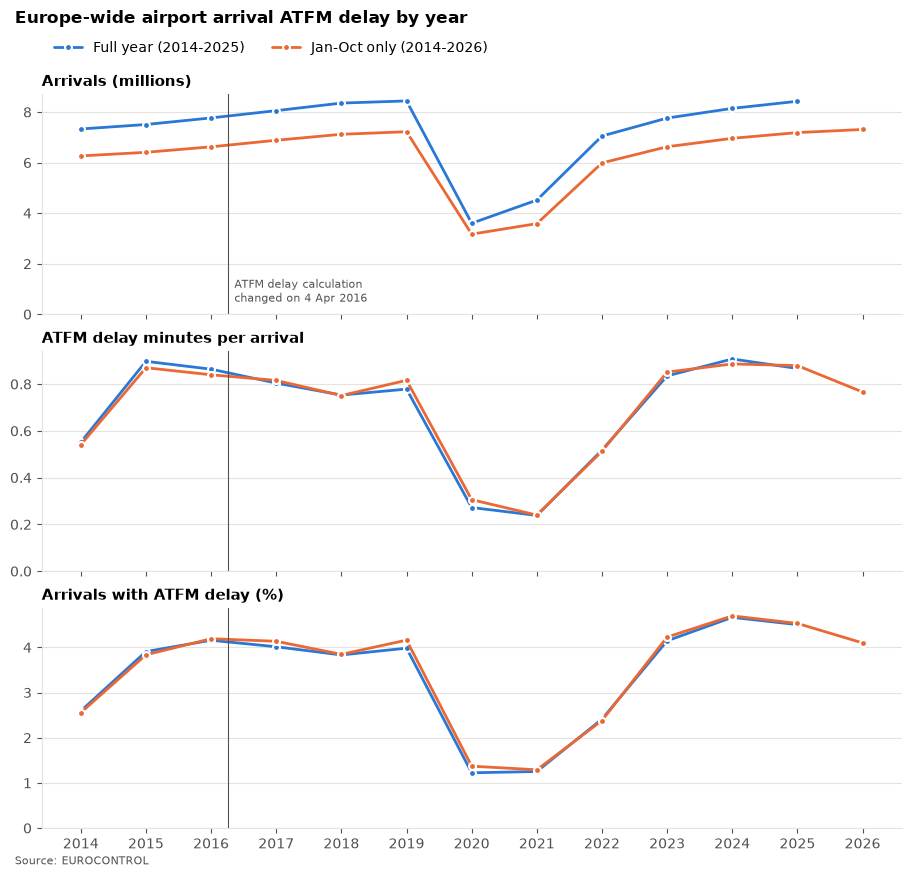

In [44]:
plot_europe_trend(trend_full, trend_same, same_label)

**Observations**

- **Traffic.** Full-year arrivals rise from 7.33 million (2014) to 8.44 million (2019), fall to 3.60 million in 2020 and 4.52 million in 2021, and are back at 8.42 million in 2025. On the same months (Jan-Oct), 2026 has the most arrivals of the period: 7.31 million, against 7.22 million in 2019.
- **The 2020-2021 drop in traffic comes with the lowest ratios.** ATFM delay per arrival falls to 0.272 and 0.238 minutes, and the share of arrivals with ATFM delay to 1.224% and 1.252%, so the ratios move with traffic in those years and are not comparable with the other years on their own.
- **Before and after.** With traffic at the same level (2019 and 2025, about 8.4 million arrivals), the share of arrivals with ATFM delay is higher in 2025 (4.505% against 3.984%), and so is the delay per arrival (0.867 against 0.778 minutes). The highest full-year values are in 2024: 0.907 minutes per arrival and 4.665% of arrivals with ATFM delay.
- **Long delays do not follow the same path.** The share of arrivals with more than 15 minutes of ATFM delay is highest in 2015 (2.242%); in 2024 it is 2.002%, although the share with any ATFM delay is higher than in 2015.
- **2026 so far.** On Jan-Oct, 2026 has the most arrivals but a lower delay per arrival (0.766 minutes) and share of arrivals with ATFM delay (4.100%) than 2023, 2024 and 2025.
- **Calculation change.** 2014 and 2015 use the earlier ATFM delay calculation, and 2016 mixes both (3.7), so the step from 2014 to 2015 and the comparisons with those years are read with that caveat.

### 5.2 Seasonality

Before months are grouped across years, ATFM delay minutes per arrival are computed for every month of every year, to see whether the same months stand out each year.

In [45]:
season_matrix = month_year_matrix(apt)
with pd.option_context("display.float_format", "{:.2f}".format):
    display(season_matrix)

YEAR,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Jan,0.34,0.77,0.85,1.09,0.60,0.50,0.51,0.14,0.27,0.38,0.53,0.78,0.88
Feb,0.36,0.65,0.78,0.75,0.60,0.67,0.83,0.09,0.23,0.54,0.48,0.40,0.71
Mar,0.25,0.63,0.75,0.52,0.60,0.91,0.31,0.02,0.21,0.54,0.61,0.59,0.58
Apr,0.35,0.59,0.49,0.44,0.57,0.58,0.00,0.01,0.48,0.82,0.72,0.63,0.46
May,0.49,0.83,0.82,0.64,0.75,0.79,0.01,0.04,0.41,1.24,0.93,0.85,0.66
Jun,0.56,0.87,1.08,0.79,0.91,1.02,0.01,0.08,0.59,1.00,0.97,0.86,0.78
Jul,0.73,1.07,1.10,1.06,0.83,1.07,0.05,0.33,0.65,1.02,1.09,1.18,0.80
Aug,0.81,1.28,0.89,1.01,0.87,0.89,0.06,0.48,0.65,0.87,0.99,1.05,0.92
Sep,0.68,1.08,0.74,1.06,0.90,0.86,0.03,0.29,0.60,1.01,1.22,1.13,0.83
Oct,0.65,0.72,0.81,0.72,0.75,0.73,0.08,0.31,0.70,0.77,0.99,1.04,0.97


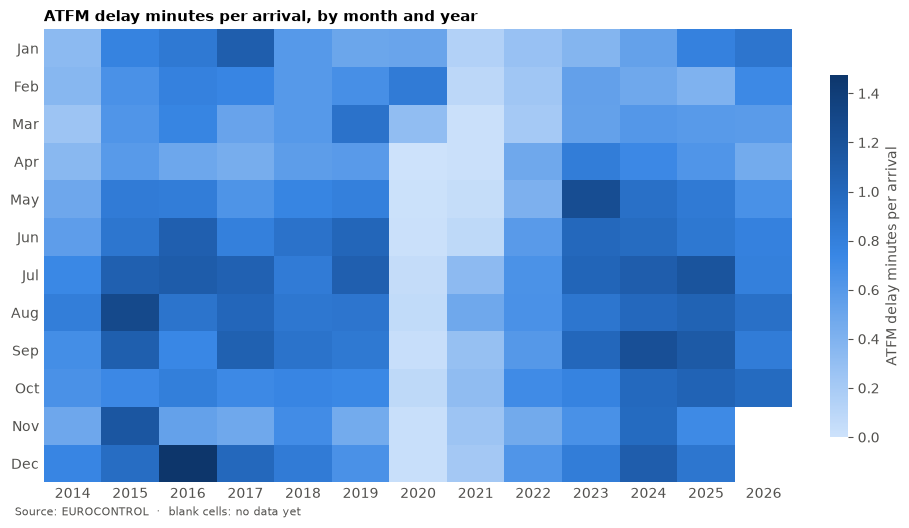

In [46]:
plot_month_year_heatmap(season_matrix, "ATFM delay minutes per arrival, by month and year",
                        "ATFM delay minutes per arrival")

The highest and lowest month of each year in the table above:

In [47]:
with pd.option_context("display.float_format", "{:.2f}".format):
    display(peak_months(season_matrix))

,highest_month,highest,lowest_month,lowest,months_with_data
year,,,,,
2014,Aug,0.81,Mar,0.25,12
2015,Aug,1.28,Apr,0.59,12
2016,Dec,1.48,Apr,0.49,12
2017,Jan,1.09,Apr,0.44,12
2018,Jun,0.91,Apr,0.57,12
2019,Jul,1.07,Nov,0.46,12
2020,Feb,0.83,Apr,0.00,12
2021,Aug,0.48,Apr,0.01,12
2022,Oct,0.70,Mar,0.21,12


**Observations: month by year**

- The highest month of the year falls in June-September in 6 of the 10 years with normal traffic (2014, 2015, 2018, 2019, 2024, 2025). In the other four it is December 2016, January 2017, October 2022 and May 2023.
- The lowest month falls in January-April in 9 of those 10 years; the exception is 2019 (November).
- The single highest cell of the heatmap is December 2016 (1.48). December reaches 1.00 minutes or more only in 2016, 2017 and 2024 (1.48, 1.00 and 1.09), so winter peaks appear in single years rather than every year.
- From April to December 2020, ATFM delay per arrival stays at or below 0.08 minutes, and 2021 stays at or below 0.48: the two light columns of the heatmap match the traffic drop seen in 5.1.
- Low months at the start of the year and high months in summer repeat across most years, so grouping the months of several years (below) is meaningful; single-year peaks such as December 2016 are kept in mind when reading the grouped profile.

**Monthly profile.** Months are then grouped over the complete years (5.1), without the two years of low traffic (2020 and 2021, see 5.1). The same profile with those two years included is shown next to it to measure their effect.

In [48]:
profile_years = [y for y in full_years if y not in LOW_TRAFFIC_YEARS]
print("Years used:", profile_years)
month_profile = seasonal_profile(apt, "month", profile_years)
month_profile_all = seasonal_profile(apt, "month", full_years)
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(pd.concat({f"without {LOW_TRAFFIC_YEARS}": month_profile,
                       f"with {LOW_TRAFFIC_YEARS}": month_profile_all}, axis=1))

Years used: [2014, 2015, 2016, 2017, 2018, 2019, 2022, 2023, 2024, 2025]


without [2020, 2021]                                                                               with [2020, 2021]                                                                              
                arrivals delay_min_per_arrival arr_with_atfm_delay_pct arr_with_atfm_delay_over_15_pct          arrivals delay_min_per_arrival arr_with_atfm_delay_pct arr_with_atfm_delay_over_15_pct
Jan              5305380                 0.622                   2.827                           1.383           6096785                 0.596                   2.731                           1.319
Feb              5101030                 0.557                   2.694                           1.246           5835379                 0.571                   2.691                           1.259
Mar              5922721                 0.571                   2.815                           1.306           6497223                 0.539                   2.645                           1.226
Apr              6464212                 0.571                   3.096                           1.343           6749443                 0.547                   2.969                           1.286
May              7118922                 0.779                   3.990                           1.878           7463258                 0.745                   3.815                           1.795
Jun              7361121                 0.870                   4.428                           2.081           7869559                 0.818                   4.166                           1.956
Jul              7748466                 0.986                   4.799                           2.364           8582096                 0.913                   4.456                           2.189
Aug              7684202                 0.933                   4.567                           2.208           8636648                 0.864                   4.243                           2.049
Sep              7429989                 0.934                   4.652                           2.209           8314141                 0.854                   4.276                           2.021
Oct              7136403                 0.791                   3.999                           1.806           7982053                 0.731                   3.696                           1.668
Nov              5801215                 0.663                   3.335                           1.487           6473423                 0.613                   3.065                           1.364
Dec              5752586                 0.909                   3.929                           1.935           6441414                 0.828                   3.601                           1.764

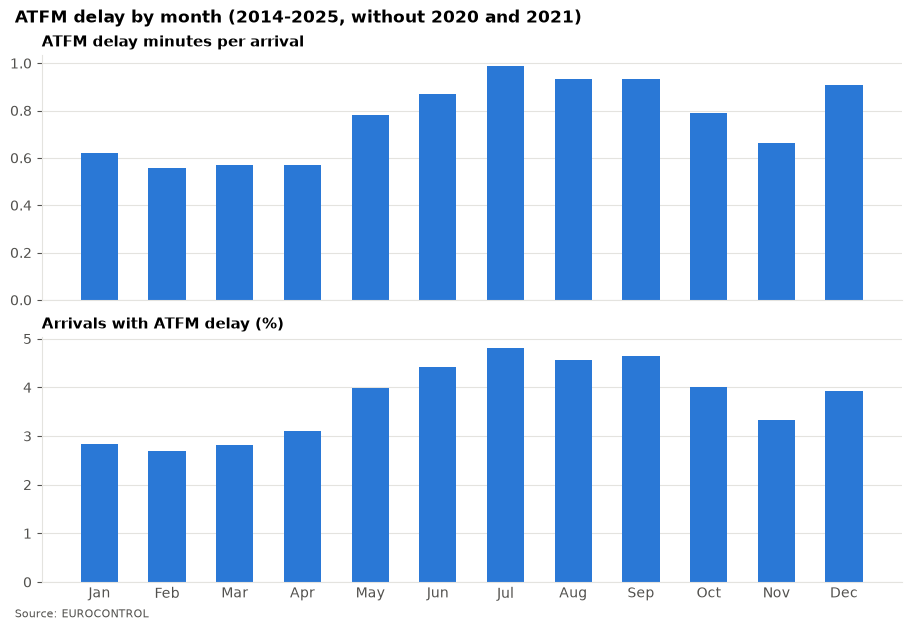

In [49]:
plot_profile(month_profile, f"ATFM delay by month ({profile_years[0]}-{profile_years[-1]}, "
                            f"without {' and '.join(map(str, LOW_TRAFFIC_YEARS))})")

**Observations: monthly profile**

- ATFM delay per arrival is lowest from January to April (0.557 to 0.622 minutes) and highest in July (0.986 minutes, 4.799% of arrivals with ATFM delay), with August and September close behind (0.933 and 0.934 minutes).
- December (0.909 minutes) is higher than October and November, but the heatmap shows that December varies more from year to year than the summer months: from 0.63 (2022) to 1.48 (2016).
- With 2020 and 2021 included, every month except February is lower (February: 0.571 against 0.557 minutes), and July is still the highest month (0.913 minutes).

**Day of the week.** The same metrics by day of the week, over the same years:

In [50]:
weekday_profile = seasonal_profile(apt, "weekday", profile_years)
weekday_profile_all = seasonal_profile(apt, "weekday", full_years)
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(pd.concat({f"without {LOW_TRAFFIC_YEARS}": weekday_profile,
                       f"with {LOW_TRAFFIC_YEARS}": weekday_profile_all}, axis=1))

without [2020, 2021]                                                                               with [2020, 2021]                                                                              
                arrivals delay_min_per_arrival arr_with_atfm_delay_pct arr_with_atfm_delay_over_15_pct          arrivals delay_min_per_arrival arr_with_atfm_delay_pct arr_with_atfm_delay_over_15_pct
Mon             11617104                 0.805                   4.039                           1.867          12810142                 0.756                   3.785                           1.747
Tue             11101503                 0.633                   3.300                           1.463          12173113                 0.593                   3.093                           1.367
Wed             11323558                 0.705                   3.598                           1.640          12472678                 0.655                   3.355                           1.522
Thu             11600198                 0.806                   3.965                           1.863          12795941                 0.753                   3.706                           1.737
Fri             11962820                 0.869                   4.211                           2.022          13257427                 0.810                   3.930                           1.882
Sat             10158341                 0.795                   3.695                           1.842          11206223                 0.750                   3.478                           1.735
Sun             11062723                 0.854                   4.117                           2.002          12225898                 0.805                   3.871                           1.881

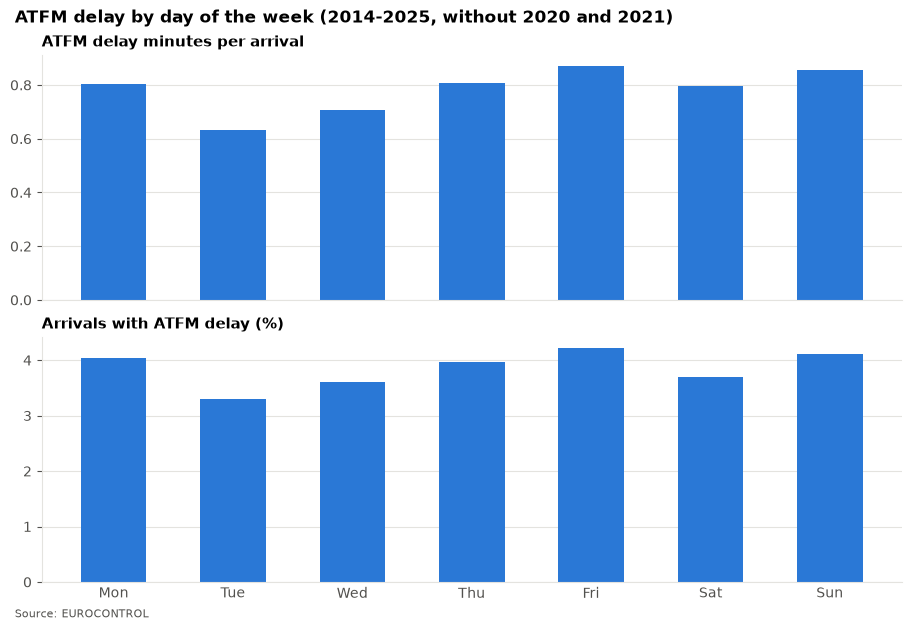

In [51]:
plot_profile(weekday_profile, f"ATFM delay by day of the week ({profile_years[0]}-{profile_years[-1]}, "
                              f"without {' and '.join(map(str, LOW_TRAFFIC_YEARS))})")

**Observations: day of the week**

- Friday has the highest values (0.869 minutes per arrival, 4.211% of arrivals with ATFM delay) and Tuesday the lowest (0.633 minutes, 3.300%). Sunday is second (0.854 minutes, 4.117%).
- Saturday has the fewest arrivals (10.16 million over these years) and a lower delay per arrival than Friday, Sunday, Monday and Thursday.

### 5.3 Airports with the highest ATFM delay per arrival

Delay per arrival is unstable at airports with little traffic (3.10 shows small airports with zero-arrival days), so rankings need a minimum of yearly arrivals. To choose it, the arrivals per airport in the latest complete year are described first.

In [52]:
ranking_year = full_years[-1]
airports_year = airport_year_totals(apt, ranking_year)
print(f"{ranking_year}: {len(airports_year)} airports, {airports_year['arrivals'].sum():,} arrivals")
airports_year["arrivals"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(0).to_frame("arrivals per airport")

2025: 289 airports, 8,424,892 arrivals


,arrivals per airport
count,289.0
mean,29152.0
std,46448.0
min,15.0
10%,870.0
25%,2499.0
50%,9614.0
75%,35712.0
90%,86632.0
max,272054.0


For each candidate minimum, the number of airports kept and their share of all arrivals and of all ATFM delay minutes in the same year:

In [53]:
with pd.option_context("display.float_format", "{:,.1f}".format):
    display(threshold_coverage(airports_year, CANDIDATE_THRESHOLDS))

,airports,airports_pct,arrivals_pct,delay_min_pct,airports_with_any_delay
min_arrivals,,,,,
5000,177,61.2,97.3,99.2,141
10000,143,49.5,94.5,97.8,120
20000,109,37.7,89.1,94.8,99
50000,46,15.9,64.1,85.1,46


Where Lisbon, Porto and Faro sit in the same distribution (rank 1 = most arrivals):

In [54]:
focus = airports_year.assign(rank_by_arrivals=range(1, len(airports_year) + 1)).loc[FOCUS_AIRPORTS]
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(focus[["name", "arrivals", "rank_by_arrivals", "delay_min_per_arrival", "arr_with_atfm_delay_pct"]])

,name,arrivals,rank_by_arrivals,delay_min_per_arrival,arr_with_atfm_delay_pct
APT_ICAO,,,,,
LPPT,Lisbon,115294,19,2.826,14.420
LPPR,Porto,56319,45,2.453,7.678
LPFR,Faro,35453,74,0.015,0.059


**Observations and decision**

- Traffic per airport is very uneven in 2025: the median airport has 9,614 arrivals and the largest 272,054; a quarter of the airports have fewer than 2,499.
- A minimum of 20,000 arrivals keeps 109 airports, which together have 89.1% of all arrivals and 94.8% of all ATFM delay minutes. Lowering it to 10,000 adds 34 airports but only 3.0 points of delay minutes (97.8%); raising it to 50,000 would exclude Faro (35,453 arrivals).
- **Decision:** airport rankings use a minimum of 20,000 arrivals in the year being ranked (`MIN_ARRIVALS_RANKING` in Setup).

**Ranking.** Airports with at least 20,000 arrivals in the latest complete year, ranked by ATFM delay minutes per arrival. Airports with no ATFM delay at all would tie at the bottom, so they are counted rather than ranked:

In [55]:
ranking = delay_ranking(apt, ranking_year, MIN_ARRIVALS_RANKING)
zero = ranking[ranking["delay_min"].eq(0)]
print(f"{ranking_year}: {len(ranking)} airports with at least {MIN_ARRIVALS_RANKING:,} arrivals; "
      f"{len(zero)} of them had no ATFM delay minutes")
print("\n".join(ranking_positions(ranking, FOCUS_AIRPORTS)))

2025: 109 airports with at least 20,000 arrivals; 10 of them had no ATFM delay minutes
LPPT Lisbon: 6th of 109 (2.826 min per arrival)
LPPR Porto: 7th of 109 (2.453 min per arrival)
LPFR Faro: 88th of 109 (0.015 min per arrival)


The 15 airports with the highest ATFM delay per arrival:

In [56]:
top = ranking.head(TOP_N)
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(top[["rank", "name", "country", "arrivals", "delay_min_per_arrival",
                 "arr_with_atfm_delay_pct", "arr_with_atfm_delay_over_15_pct"]])

,rank,name,country,arrivals,delay_min_per_arrival,arr_with_atfm_delay_pct,arr_with_atfm_delay_over_15_pct
APT_ICAO,,,,,,,
LGAV,1,Athens,Greece,139315,5.461,31.264,13.831
EHAM,2,Amsterdam Schiphol,Netherlands,246511,4.829,30.713,9.295
LFMN,3,Nice-Côte d’Azur,France,76083,4.121,15.521,9.366
LGIR,4,Heraklion,Greece,33258,3.928,21.225,10.401
LLBG,5,Tel Aviv,Israel,70359,3.801,16.532,9.179
LPPT,6,Lisbon,Portugal,115294,2.826,14.420,6.512
LPPR,7,Porto,Portugal,56319,2.453,7.678,4.954
LSZH,8,Zürich,Switzerland,133877,2.440,14.584,5.524
LIRN,9,Naples,Italy,45721,2.339,10.533,5.345


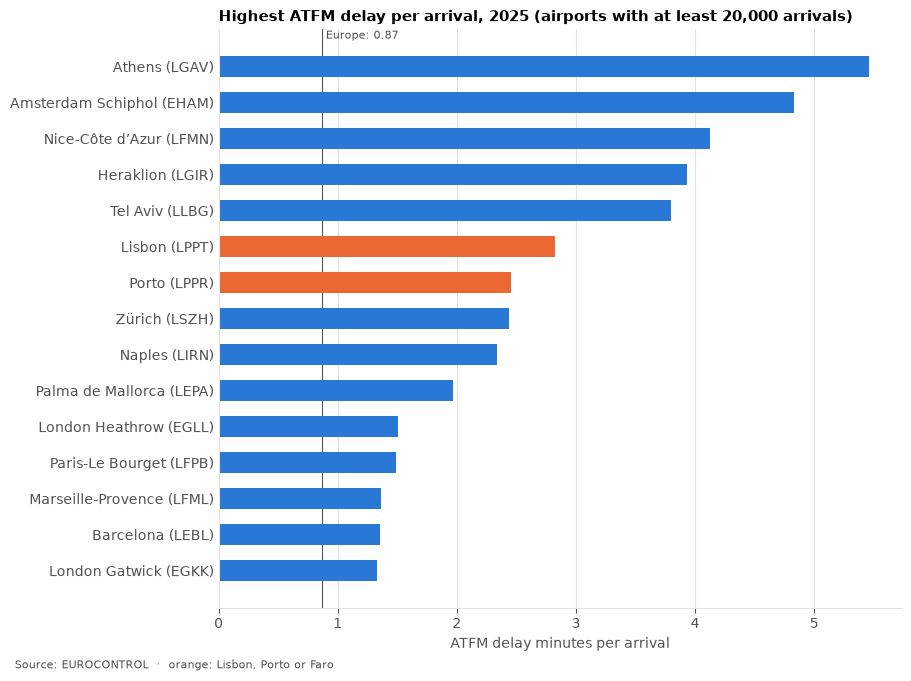

In [57]:
europe_ranking_year = trend_full.loc[ranking_year, "delay_min_per_arrival"]
plot_top_airports(top, europe_ranking_year,
                  f"Highest ATFM delay per arrival, {ranking_year} "
                  f"(airports with at least {MIN_ARRIVALS_RANKING:,} arrivals)")

**Observations: ranking**

- In 2025, 109 airports had at least 20,000 arrivals; 10 of them had no ATFM delay minutes.
- Athens has the highest ATFM delay per arrival (5.461 minutes), followed by Amsterdam Schiphol (4.829). At both, more than 30% of arrivals had ATFM delay (31.264% and 30.713%).
- **Lisbon is 6th of 109 (2.826 minutes per arrival) and Porto 7th (2.453)**, both above the Europe-wide value of 0.87 minutes (5.1). Faro is 88th of 109 (0.015 minutes).
- The share of arrivals with ATFM delay does not follow the same order as delay per arrival: Porto has 7.678% of arrivals with ATFM delay against 14.584% at Zürich, which is ranked just below it (2.440 minutes).

**Stability.** The same ranking for the two previous complete years, for the airports of the top 15 above and for Lisbon, Porto and Faro (each year applies the minimum to its own arrivals; an empty rank means the airport was below the minimum that year):

In [58]:
stability_years = full_years[-3:]
stability_airports = list(dict.fromkeys([*top.index, *FOCUS_AIRPORTS]))
stability = ranks_across_years(apt, stability_years, MIN_ARRIVALS_RANKING, stability_airports)
for year in stability_years:
    print(f"{year}: {len(delay_ranking(apt, year, MIN_ARRIVALS_RANKING))} airports ranked")
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(stability)

2023: 103 airports ranked
2024: 104 airports ranked
2025: 109 airports ranked


,name,rank 2023,min/arr 2023,rank 2024,min/arr 2024,rank 2025,min/arr 2025
APT_ICAO,,,,,,,
LGAV,Athens,4,3.244,5,3.460,1,5.461
EHAM,Amsterdam Schiphol,7,2.678,2,3.792,2,4.829
LFMN,Nice-Côte d’Azur,20,1.015,13,1.708,3,4.121
LGIR,Heraklion,5,3.120,6,3.376,4,3.928
LLBG,Tel Aviv,2,4.699,10,1.867,5,3.801
LPPT,Lisbon,1,4.884,1,4.199,6,2.826
LPPR,Porto,22,0.885,7,3.017,7,2.453
LSZH,Zürich,14,1.503,11,1.791,8,2.440
LIRN,Naples,36,0.480,15,1.547,9,2.339


In [59]:
for year in stability_years[:-1]:
    top_then = delay_ranking(apt, year, MIN_ARRIVALS_RANKING).head(TOP_N).index
    print(f"Top {TOP_N} of {ranking_year} also in the top {TOP_N} of {year}: {len(set(top.index) & set(top_then))}")
    print("  " + "; ".join(ranking_positions(delay_ranking(apt, year, MIN_ARRIVALS_RANKING), FOCUS_AIRPORTS)))

Top 15 of 2025 also in the top 15 of 2023: 10
  LPPT Lisbon: 1st of 103 (4.884 min per arrival); LPPR Porto: 22nd of 103 (0.885 min per arrival); LPFR Faro: 94th of 103 (0.002 min per arrival)
Top 15 of 2025 also in the top 15 of 2024: 13
  LPPT Lisbon: 1st of 104 (4.199 min per arrival); LPPR Porto: 7th of 104 (3.017 min per arrival); LPFR Faro: 79th of 104 (0.063 min per arrival)


**Observations: stability**

- 10 of the 15 airports of the 2025 top 15 were also in the top 15 of 2023, and 13 in the top 15 of 2024, so the list of most affected airports changes little from year to year.
- Athens, Amsterdam Schiphol and Heraklion are in the top 7 in all three years.
- **Lisbon was 1st in 2023 (4.884 minutes per arrival) and 2024 (4.199)** and 6th in 2025 (2.826): it stays near the top while its delay per arrival falls each year.
- **Porto moved from 22nd in 2023 (0.885 minutes) to 7th in 2024 (3.017) and 7th in 2025 (2.453).**
- Faro stays near the bottom (94th, 79th and 88th), with at most 0.063 minutes per arrival.
- Some airports move a lot: Nice-Côte d’Azur went from 20th (2023) to 3rd (2025), and London Gatwick from 3rd (2023) to 15th (2025).

### 5.4 Causes of ATFM delay

Each ATFM delay minute carries a delay code. The [dataset reference page](https://ansperformance.eu/reference/dataset/airport-arrival-atfm-delay/) gives each code a label and a "Reason Group". The table reproduces them as listed there; the groups are used below without the "AD" (aerodrome) prefix that all of them share.

In [60]:
codes = delay_code_table()
missing_columns = set(codes["column"]) - set(apt.columns)
print(f"{len(codes)} codes, {codes['group used here'].nunique()} groups; code columns missing from the data: {missing_columns or 'none'}")
codes

16 codes, 7 groups; code columns missing from the data: none


,label on the page,Reason Group on the page,group used here,column
code,,,,
A,A - Accident/Incident - AD,AD Disruptions,Disruptions,DLY_APT_ARR_A_1
C,C - ATC Capacity - AD,AD Capacity (ATC),Capacity (ATC),DLY_APT_ARR_C_1
D,D - De-icing - AD,AD Weather,Weather,DLY_APT_ARR_D_1
E,E - Equipment (non-ATC) - AD,AD Disruptions,Disruptions,DLY_APT_ARR_E_1
G,G - Aerodrome Capacity - AD,AD Capacity,Capacity,DLY_APT_ARR_G_1
I,I - Industrial Action (ATC) - AD,AD Disruptions (ATC),Disruptions (ATC),DLY_APT_ARR_I_1
M,M - Airspace Management - AD,AD Capacity,Capacity,DLY_APT_ARR_M_1
N,N - Industrial Action (non-ATC) - AD,AD Disruptions,Disruptions,DLY_APT_ARR_N_1
O,O - Other - AD,AD Disruptions,Disruptions,DLY_APT_ARR_O_1


**Europe-wide.** ATFM delay minutes per group over the complete years without 2020 and 2021 (as in 5.2), with each code's minutes for reference:

In [61]:
base = apt[apt["YEAR"].isin(profile_years)]
europe_groups = group_minutes(base).sum()
with pd.option_context("display.float_format", "{:,.1f}".format):
    display(pd.DataFrame({"minutes": europe_groups, "share_pct": europe_groups / europe_groups.sum() * 100}))
    code_minutes = base[codes["column"]].sum().set_axis(codes.index)
    display(pd.DataFrame({"group": codes["group used here"], "minutes": code_minutes,
                          "share_pct": code_minutes / code_minutes.sum() * 100}).sort_values("minutes", ascending=False))

,minutes,share_pct
group used here,,
Capacity,20192307,32.8
Weather,27425318,44.5
Capacity (ATC),7123872,11.6
Staffing (ATC),2322834,3.8
Disruptions (ATC),1956040,3.2
Disruptions,1270017,2.1
Events,1348318,2.2


,group,minutes,share_pct
code,,,
W,Weather,27411786,44.5
G,Capacity,18860676,30.6
C,Capacity (ATC),7123872,11.6
S,Staffing (ATC),2322834,3.8
T,Disruptions (ATC),1382865,2.2
P,Events,1348318,2.2
V,Capacity,874685,1.4
O,Disruptions,809091,1.3
I,Disruptions (ATC),573175,0.9


**Observations: Europe-wide**

- Over the years with normal traffic, three groups hold most ATFM delay minutes: Weather (44.5%), Capacity (32.8%) and Capacity (ATC) (11.6%).
- Within them, two codes dominate: W, Weather (44.5% of all minutes), and G, Aerodrome Capacity (30.6%). De-icing (D), the other weather code, adds almost nothing (13,532 minutes).
- Code NA (not specified) has no minutes and R (ATC Routeing) only 296.

**By year.** Shares of each group in every complete year, with the total ATFM delay minutes of the year. 2020 and 2021 are the low-traffic years of 5.1, so their shares rest on far fewer minutes.

In [62]:
year_minutes = group_minutes(apt[apt["YEAR"].isin(full_years)], by="YEAR")
year_shares = group_shares(year_minutes)
with pd.option_context("display.float_format", "{:,.1f}".format):
    display(year_shares.assign(total_minutes=year_minutes.sum(axis=1)))

group used here,Capacity,Weather,Capacity (ATC),Staffing (ATC),Disruptions (ATC),Disruptions,Events,total_minutes
YEAR,,,,,,,,
2014,25.3,59.1,6.6,2.0,3.0,2.3,1.7,4041415
2015,47.0,41.9,3.2,0.7,1.3,3.8,2.1,6734511
2016,45.8,43.6,4.8,1.8,2.1,1.2,0.7,6707573
2017,37.6,47.0,8.0,0.9,2.8,1.8,2.0,6476861
2018,31.3,49.4,11.2,2.6,1.8,1.2,2.5,6289978
2019,28.8,42.6,15.6,3.5,3.0,2.3,4.2,6568644
2020,12.1,67.8,4.4,2.9,6.9,5.1,0.8,979625
2021,21.2,34.5,31.4,3.3,5.2,3.4,1.1,1076215
2022,28.0,35.8,14.3,10.0,4.4,2.4,4.9,3650126


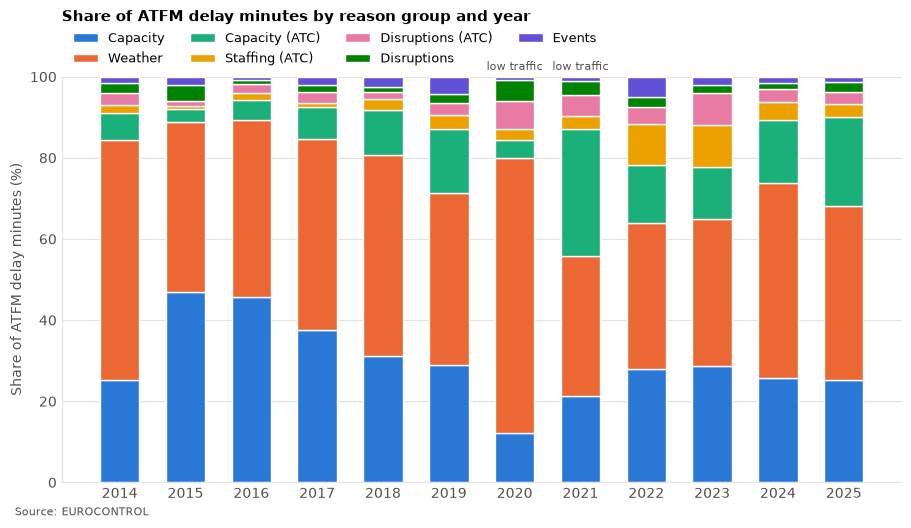

In [63]:
plot_group_shares(year_shares, "Share of ATFM delay minutes by reason group and year",
                  notes={str(y): "low traffic" for y in LOW_TRAFFIC_YEARS})

**Observations: causes by year**

- Weather is the largest group in every complete year except 2015 and 2016, when Capacity is larger (47.0% and 45.8%).
- Capacity (ATC) grows from 3.2% of the minutes in 2015 to 15.6% in 2019 and 21.8% in 2025, its highest share in a year with normal traffic (2021, a low-traffic year, has 31.4% of a much smaller total).
- Staffing (ATC) reaches 10.0% in 2022 and 10.3% in 2023, against 4.6% or less in every other year.
- 2020 and 2021 have about 1 million ATFM delay minutes each (979,625 and 1,076,215), against 3.6 to 7.4 million in the other years, so their shares are read with care.

**By airport.** The same shares for the top 15 of the ranking in 5.3 and for Lisbon, Porto and Faro, in the same year, with each airport's total ATFM delay minutes. Shares based on fewer than 1,000 minutes (`FEW_MINUTES`) are flagged, because a handful of delayed flights decides them.

In [64]:
cause_airports = list(dict.fromkeys([*top.index, *FOCUS_AIRPORTS]))
year_data = apt[apt["YEAR"] == ranking_year]
airport_minutes = group_minutes(year_data, by="APT_ICAO").loc[cause_airports]
airport_shares = group_shares(airport_minutes)
airport_table = airport_shares.copy()
airport_table.insert(0, "total_minutes", airport_minutes.sum(axis=1))
airport_table.insert(0, "name", airports_year.loc[cause_airports, "name"])
airport_table["note"] = ["few minutes" if m < FEW_MINUTES else "" for m in airport_table["total_minutes"]]
with pd.option_context("display.float_format", "{:,.1f}".format):
    display(airport_table)

group used here,name,total_minutes,Capacity,Weather,Capacity (ATC),Staffing (ATC),Disruptions (ATC),Disruptions,Events,note
APT_ICAO,,,,,,,,,,
LGAV,Athens,760787,4.1,3.7,90.5,0.0,1.8,0.0,0.0,
EHAM,Amsterdam Schiphol,1190455,49.8,48.7,0.1,0.0,0.0,0.0,1.4,
LFMN,Nice-Côte d’Azur,313556,2.0,13.5,73.8,10.1,0.5,0.1,0.0,
LGIR,Heraklion,130654,98.6,0.7,0.7,0.0,0.0,0.1,0.0,
LLBG,Tel Aviv,267442,15.2,0.0,83.6,0.0,0.9,0.4,0.0,
LPPT,Lisbon,325836,28.9,68.7,0.7,0.2,0.2,0.7,0.7,
LPPR,Porto,138147,11.4,73.2,0.0,3.8,10.1,1.4,0.0,
LSZH,Zürich,326660,20.5,48.4,0.3,2.4,0.0,22.2,6.1,
LIRN,Naples,106958,48.6,26.7,0.0,0.0,24.7,0.0,0.0,


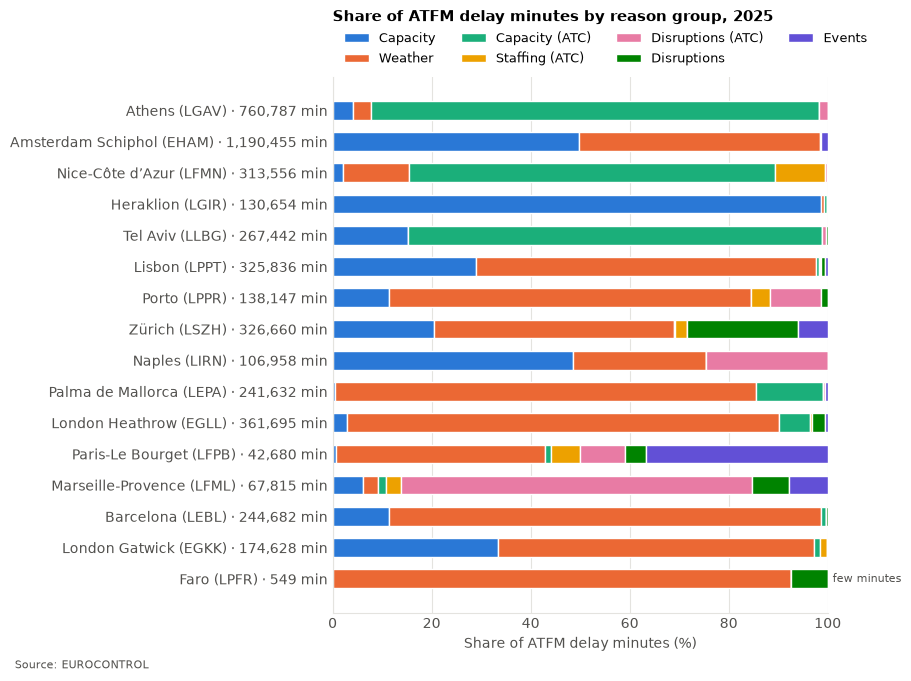

In [65]:
labelled = airport_shares.set_axis([f"{airports_year.loc[i, 'name']} ({i}) · {m:,.0f} min"
                                    for i, m in airport_minutes.sum(axis=1).items()])
few = {label: "few minutes" for label, m in zip(labelled.index, airport_minutes.sum(axis=1)) if m < FEW_MINUTES}
plot_group_shares(labelled, f"Share of ATFM delay minutes by reason group, {ranking_year}", horizontal=True, notes=few)

**Observations: causes by airport (2025)**

- The leading cause differs by airport. At Athens (90.5%), Tel Aviv (83.6%) and Nice-Côte d’Azur (73.8%) most ATFM delay minutes are Capacity (ATC); at Heraklion 98.6% are Capacity (aerodrome capacity codes); at Marseille-Provence 71.0% are Disruptions (ATC).
- **Lisbon and Porto are mainly weather-related**: Weather is 68.7% of Lisbon's 325,836 minutes and 73.2% of Porto's 138,147 minutes. The second group is Capacity at Lisbon (28.9%); at Porto it is Capacity (11.4%), closely followed by Disruptions (ATC) (10.1%).
- Lisbon's mix is close to London Gatwick's (63.9% Weather, 33.5% Capacity). Weather is an even larger share at London Heathrow (87.3%), Barcelona (87.2%) and Palma de Mallorca (85.1%).
- **Faro's shares rest on 549 minutes in the whole year** (92.5% Weather), so they describe a few delayed flights rather than a pattern.

### 5.5 Lisbon, Porto and Faro against airports of similar traffic

**Peers.** For each of the three airports, all airports of the latest complete year are ordered by arrivals, and the 5 airports just above and the 5 just below it are its traffic peers (10 peers). The peers are chosen once, from the arrivals of that year, and kept fixed for every year shown below, so the comparison follows the same airports over time (`traffic_peers` in Setup).

In [66]:
peers = {icao: traffic_peers(airports_year, icao) for icao in FOCUS_AIRPORTS}
focus_names = airports_year.loc[FOCUS_AIRPORTS, "name"].to_dict()
for icao, peer_list in peers.items():
    arrivals = airports_year.loc[[icao, *peer_list], "arrivals"]
    print(f"{icao} {focus_names[icao]} ({arrivals[icao]:,} arrivals in {ranking_year}): peers from "
          f"{arrivals[peer_list].min():,} to {arrivals[peer_list].max():,} arrivals")

LPPT Lisbon (115,294 arrivals in 2025): peers from 101,522 to 128,359 arrivals
LPPR Porto (56,319 arrivals in 2025): peers from 46,851 to 62,942 arrivals
LPFR Faro (35,453 arrivals in 2025): peers from 33,542 to 36,971 arrivals


**Comparison table.** For each airport and its peers: metrics in the latest complete year, its rank in the ranking of 5.3 (empty when below the arrivals minimum), and the metrics over the last three complete years together. The last row is the median of the 10 peers.

In [67]:
period = stability_years
for icao in FOCUS_AIRPORTS:
    print(f"--- {icao} {focus_names[icao]}")
    with pd.option_context("display.float_format", "{:,.3f}".format):
        display(peer_table(apt, icao, peers[icao], ranking_year, period, ranking))

--- LPPT Lisbon


,name,country,arrivals 2025,min/arr 2025,ATFM delay % 2025,over 15 min % 2025,rank 2025,min/arr 2023-2025,ATFM delay % 2023-2025,role
APT_ICAO,,,,,,,,,,
LPPT,Lisbon,Portugal,115294,2.826,14.420,6.512,6,3.964,21.941,airport
EKCH,Copenhagen Kastrup,Denmark,128359,0.548,4.064,1.286,36,1.329,6.570,peer
EIDW,Dublin,Ireland,127668,0.332,1.272,0.719,45,0.349,1.456,peer
LOWW,Vienna,Austria,126819,0.794,3.561,1.962,26,0.654,2.783,peer
LEPA,Palma de Mallorca,Spain,122586,1.971,7.912,3.675,10,1.798,7.026,peer
LTAI,Antalya,Türkiye,116428,0.897,7.403,1.912,22,1.788,10.606,peer
LIMC,Milan Malpensa,Italy,113154,0.356,1.570,0.960,44,0.379,1.633,peer
ENGM,Oslo Gardermoen,Norway,111801,0.237,1.089,0.449,58,0.356,1.745,peer
LFPO,Paris-Orly,France,109463,0.895,4.782,1.941,23,1.264,6.869,peer


--- LPPR Porto


,name,country,arrivals 2025,min/arr 2025,ATFM delay % 2025,over 15 min % 2025,rank 2025,min/arr 2023-2025,ATFM delay % 2023-2025,role
APT_ICAO,,,,,,,,,,
LPPR,Porto,Portugal,56319,2.453,7.678,4.954,7,2.134,7.175,airport
LEAL,Alicante,Spain,62942,0.147,1.088,0.345,67,0.131,0.872,peer
EGPH,Edinburgh,United Kingdom,62348,0.581,3.367,1.350,32,0.383,2.157,peer
LIML,Milan Linate,Italy,60913,0.290,1.358,0.734,50,0.209,1.048,peer
EDDH,Hamburg,Germany,60910,0.012,0.102,0.023,91,0.031,0.160,peer
EDDK,Cologne-Bonn,Germany,58532,0.558,3.960,1.341,35,0.723,5.328,peer
LIME,Bergamo,Italy,52320,0.221,1.074,0.556,59,0.196,0.751,peer
EGBB,Birmingham,United Kingdom,49962,0.328,1.127,0.755,46,0.168,0.570,peer
LFML,Marseille-Provence,France,49716,1.364,7.135,2.806,13,1.170,5.392,peer


--- LPFR Faro


,name,country,arrivals 2025,min/arr 2025,ATFM delay % 2025,over 15 min % 2025,rank 2025,min/arr 2023-2025,ATFM delay % 2023-2025,role
APT_ICAO,,,,,,,,,,
LPFR,Faro,Portugal,35453,0.015,0.059,0.037,88,0.027,0.109,airport
EGPF,Glasgow,United Kingdom,36971,0.000,0.003,0.000,99,0.014,0.050,peer
GCRR,Lanzarote,Spain,35990,0.995,4.418,2.301,19,1.129,4.931,peer
GMMX,Marrakech,Morocco,35914,0.000,0.000,0.000,100,0.039,0.115,peer
ELLX,Luxembourg,Luxembourg,35910,0.150,1.005,0.256,66,0.686,7.367,peer
EBCI,Charleroi,Belgium,35712,0.025,0.179,0.070,85,0.018,0.092,peer
EDDP,Leipzig-Halle,Germany,35404,0.180,1.265,0.432,62,0.524,4.207,peer
LATI,Tirana,Albania,35033,0.037,0.183,0.094,81,0.014,0.071,peer
LFBO,Toulouse-Blagnac,France,34658,0.780,4.345,2.037,27,0.455,2.731,peer


**Observations: comparison with peers**

- **Lisbon** (2.826 minutes per arrival in 2025) is above all 10 of its peers; the closest is Palma de Mallorca (1.971), and the peer median is 0.671. Over 2023-2025 the gap is larger: 3.964 against a peer median of 0.615, with 21.941% of arrivals with ATFM delay against 2.540%.
- **Porto** (2.453 in 2025) is also above all its peers; the closest is Marseille-Provence (1.364) and the peer median is 0.256. Over 2023-2025: 2.134 against 0.182.
- **Faro** (0.015 in 2025) is below its peer median (0.061), and over 2023-2025 too (0.027 against 0.065). Among its peers, Lanzarote (0.995) and Toulouse-Blagnac (0.780) have far more ATFM delay per arrival.
- The peers are close in traffic: from 101,522 to 128,359 arrivals for Lisbon, 46,851 to 62,942 for Porto and 33,542 to 36,971 for Faro.

**Over time.** ATFM delay minutes per arrival of each airport and the median of its fixed peers, for every complete year. Each panel has its own vertical scale; 2020 and 2021 (low traffic, 5.1) are shaded.

In [68]:
evolution = {icao: airport_vs_peers_by_year(apt, icao, peers[icao], full_years) for icao in FOCUS_AIRPORTS}
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(pd.concat(evolution, axis=1))

LPPT                              LPPR                              LPFR                            
      LPPT peer median peers with data  LPPR peer median peers with data  LPFR peer median peers with data
year                                                                                                      
2014 0.631       0.166              10 0.740       0.024              10 0.126       0.022              10
2015 0.792       0.505              10 0.867       0.023              10 0.059       0.000              10
2016 0.881       0.489              10 0.933       0.027              10 0.003       0.060              10
2017 1.650       0.604              10 1.224       0.116              10 0.000       0.046              10
2018 3.824       0.360              10 2.032       0.087              10 0.015       0.051              10
2019 4.133       0.320              10 3.092       0.062              10 0.033       0.051              10
2020 1.723       0.093              10 0.772       0.032              10 0.000       0.012              10
2021 0.279       0.069              10 2.141       0.026              10 0.001       0.022              10
2022 3.963       0.267              10 1.893       0.077              10 0.014       0.020              10
2023 4.884       0.359              10 0.885       0.067              10 0.002       0.023              10
2024 4.199       0.591              10 3.017       0.213              10 0.063       0.143              10
2025 2.826       0.671              10 2.453       0.256              10 0.015       0.061              10

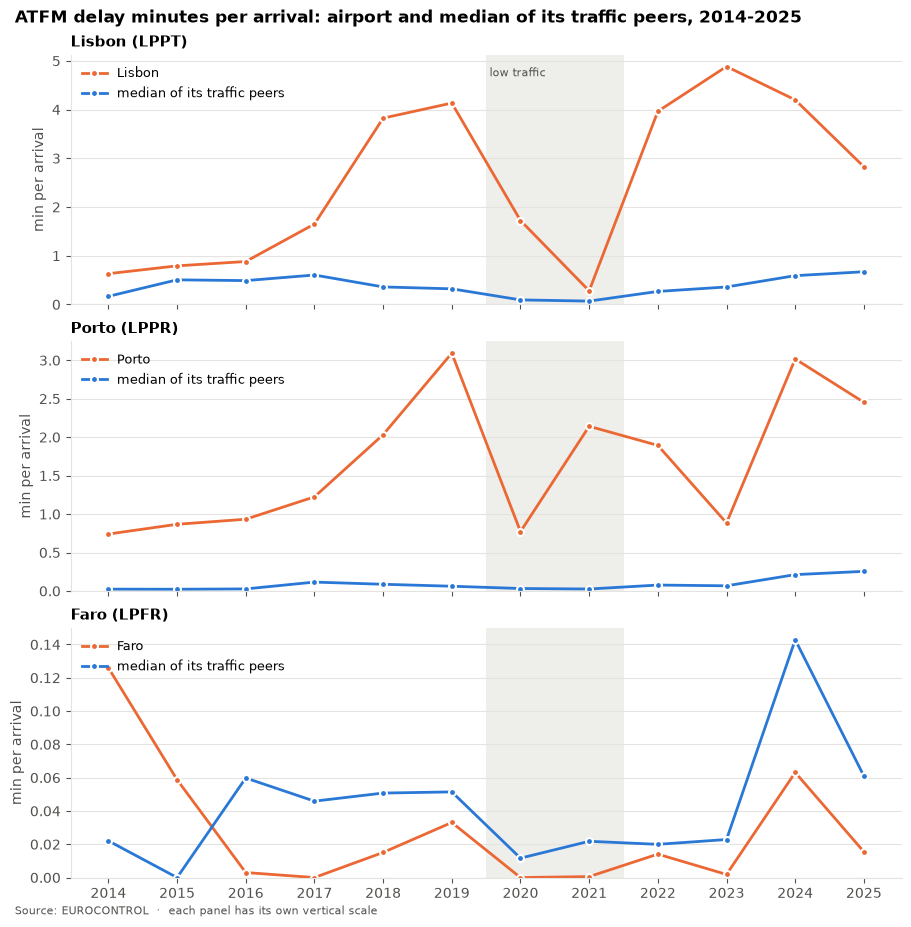

In [69]:
plot_airports_vs_peers(evolution, focus_names,
                       f"ATFM delay minutes per arrival: airport and median of its traffic peers, "
                       f"{full_years[0]}-{full_years[-1]}")

**Observations: over time**

- **Lisbon** is above the median of its peers in every year from 2014 to 2025. It rises from 0.881 minutes per arrival in 2016 to 4.133 in 2019, is back at 3.963 in 2022 and peaks at 4.884 in 2023, then falls to 4.199 (2024) and 2.826 (2025). The peer median never exceeds 0.671.
- **Porto** is also above its peer median in every year, with peaks in 2019 (3.092) and 2024 (3.017) and a low in 2023 (0.885). In 2021, a low-traffic year, Porto still has 2.141 minutes per arrival. Its peer median never exceeds 0.256.
- **Faro** is below its peer median in every year since 2016 and never above 0.126 minutes per arrival (2014). Both lines stay close to zero, so its own vertical scale exaggerates small differences.

**Weather by month.** Weather minutes and all other ATFM delay minutes, month by month, over the last three complete years together, with each month's share of the airport's weather minutes over those years:

In [70]:
monthly_weather = {icao: weather_by_month(apt, icao, period) for icao in FOCUS_AIRPORTS}
with pd.option_context("display.float_format", "{:,.1f}".format):
    display(pd.concat({focus_names[k]: v for k, v in monthly_weather.items()}, axis=1))

Lisbon                                           Porto                                            Faro                                    
    weather_min other_min weather_share_of_year_pct weather_min other_min weather_share_of_year_pct weather_min other_min weather_share_of_year_pct
Jan       47853     38371                       8.1        7460      4656                       3.2           0         0                       0.0
Feb       55665     36243                       9.4        1020      2845                       0.4           0         0                       0.0
Mar       91656     60741                      15.5        2887      3605                       1.2         254         0                      22.1
Apr       61976     71551                      10.5        6592      4092                       2.8           0         0                       0.0
May       29742     81171                       5.0       14268      8287                       6.0           0         0                       0.0
Jun       52719     63532                       8.9       13099     16482                       5.5         378         0                      32.9
Jul        8064    103598                       1.4       32992     16831                      14.0           0         0                       0.0
Aug         866    101482                       0.1       69586     12731                      29.5          56      1472                       4.9
Sep       38266     90105                       6.5       32740     12421                      13.9         460         0                      40.1
Oct       59941     59954                      10.1       47116     12115                      20.0           0        62                       0.0
Nov       91700     25982                      15.5        4638     10637                       2.0           0         0                       0.0
Dec       53817     35618                       9.1        3648      4868                       1.5           0        41                       0.0

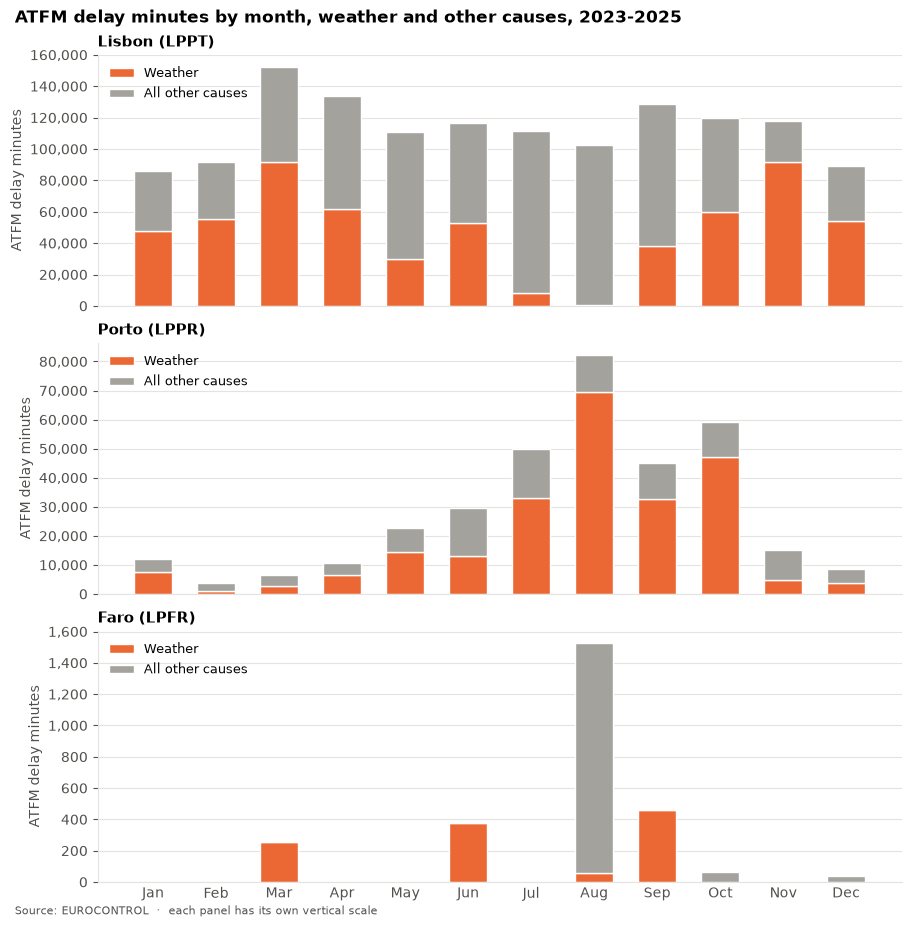

In [71]:
plot_weather_by_month(monthly_weather, focus_names,
                      f"ATFM delay minutes by month, weather and other causes, {period[0]}-{period[-1]}")

**Observations: weather by month (2023-2025)**

- **Lisbon:** weather minutes are spread over the year, with the most in March and November (91,656 and 91,700 minutes, 15.5% of the year's weather minutes each). In July and August there are almost none (8,064 and 866), while the other causes stay high (103,598 and 101,482 minutes), so Lisbon's summer ATFM delay is not weather-related.
- **Porto:** weather minutes are concentrated from July to October, each of these months holding at least 13.9% of the weather minutes; August alone holds 29.5% (69,586 minutes) and October 20.0%. February has the fewest (1,020).
- **Faro:** ATFM delay minutes appear in only six months of the table, the largest being August (56 weather and 1,472 other minutes). As in 5.4, these are too few minutes to describe a seasonal pattern.

The weather-by-month table shows that most of Lisbon's ATFM delay minutes in July and August are not Weather. The shares of every reason group in Lisbon's minutes, month by month, over the same years:

In [72]:
lisbon_groups = airport_group_shares_by_month(apt, "LPPT", period)
with pd.option_context("display.float_format", "{:,.1f}".format):
    display(lisbon_groups)

group used here,Capacity,Weather,Capacity (ATC),Staffing (ATC),Disruptions (ATC),Disruptions,Events,total_minutes
Jan,37.5,55.5,3.5,1.1,0.0,0.0,2.5,86224
Feb,36.5,60.6,0.6,2.0,0.3,0.0,0.0,91908
Mar,31.1,60.1,6.1,2.7,0.0,0.0,0.0,152397
Apr,41.5,46.4,10.4,0.8,0.6,0.3,0.0,133527
May,39.8,26.8,9.3,0.1,0.0,0.0,24.0,110913
Jun,48.6,45.3,4.0,2.0,0.0,0.0,0.0,116251
Jul,72.3,7.2,15.3,2.7,0.2,2.4,0.0,111662
Aug,82.1,0.8,10.5,2.7,1.1,0.6,2.2,102348
Sep,64.2,29.8,5.2,0.5,0.0,0.2,0.0,128371
Oct,41.9,50.0,6.2,0.0,1.5,0.4,0.0,119895


In July and August, the Capacity group (codes G, M, R and V, see 5.4) holds 72.3% and 82.1% of Lisbon's ATFM delay minutes, and Weather 7.2% and 0.8%. Capacity is also the largest group in May (39.8%), June (48.6%) and September (64.2%). From October to April, Weather is the largest group in every month.

## 6. Conclusions

### 6.1 Results

Europe-wide values and the three Portuguese airports in the latest complete year, with the last three complete years together and the main reason group of the year (all values are taken from the variables computed in section 5):

In [73]:
europe_year_shares = year_shares.loc[ranking_year]
rows = [summary_row("Europe (all airports)", trend_full.loc[ranking_year],
                    europe_metrics(apt[apt["YEAR"].isin(period)])["delay_min_per_arrival"],
                    europe_year_shares.idxmax(), europe_year_shares.max())]
for icao in FOCUS_AIRPORTS:
    shares = airport_shares.loc[icao]
    rows.append(summary_row(
        f"{focus_names[icao]} ({icao})", airports_year.loc[icao],
        airport_period_totals(apt, period).loc[icao, "delay_min_per_arrival"],
        shares.idxmax(), shares.max(),
        rank=f"{ordinal(ranking.loc[icao, 'rank'])} of {len(ranking)}",
        peer_median=airports_year.loc[peers[icao], "delay_min_per_arrival"].median(),
    ))
results = pd.DataFrame(rows).set_index("")
print(f"year = {ranking_year}; 3 years = {period[0]}-{period[-1]}; "
      f"rank among airports with at least {MIN_ARRIVALS_RANKING:,} arrivals")
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(results)
latest = trend_same.index.max()
print(f"Europe, {same_label} {latest}: {trend_same.loc[latest, 'delay_min_per_arrival']:.3f} min per arrival, "
      f"{trend_same.loc[latest, 'arr_with_atfm_delay_pct']:.3f}% of arrivals with ATFM delay "
      f"({same_label} {latest - 1}: {trend_same.loc[latest - 1, 'delay_min_per_arrival']:.3f} and "
      f"{trend_same.loc[latest - 1, 'arr_with_atfm_delay_pct']:.3f}%)")

year = 2025; 3 years = 2023-2025; rank among airports with at least 20,000 arrivals


,min/arr (year),ATFM delay % (year),rank (year),peer median min/arr (year),min/arr (3 years),main cause (year)
,,,,,,
Europe (all airports),0.867,4.505,,,0.870,Weather (43.0%)
Lisbon (LPPT),2.826,14.420,6th of 109,0.671,3.964,Weather (68.7%)
Porto (LPPR),2.453,7.678,7th of 109,0.256,2.134,Weather (73.2%)
Faro (LPFR),0.015,0.059,88th of 109,0.061,0.027,Weather (92.5%)


Europe, Jan-Oct 2026: 0.766 min per arrival, 4.100% of arrivals with ATFM delay (Jan-Oct 2025: 0.879 and 4.532%)


### 6.2 Key findings

1. **Europe-wide ATFM delay is above its pre-2020 level.** With almost the same traffic (8.42 million arrivals in 2025, 8.44 million in 2019), ATFM delay per arrival is 0.867 minutes in 2025 against 0.778 in 2019, and the highest complete year is 2024 (0.907). In January-October 2026 it is lower than a year earlier (0.766 against 0.879 minutes) although traffic is the highest of the period (5.1, 6.1).
2. **ATFM delay is seasonal.** July is the highest month (0.986 minutes per arrival) and January to April the lowest (0.557 to 0.622), and the lowest month of a year falls in January-April in 9 of 10 years with normal traffic. By day of the week, Friday is the highest and Tuesday the lowest (5.2).
3. **Weather and capacity account for most ATFM delay, but the mix differs by airport.** Over the years with normal traffic, Weather holds 44.5% of all minutes, Capacity 32.8% and Capacity (ATC) 11.6%; Capacity (ATC) grows from 3.2% in 2015 to 21.8% in 2025. At Athens, Tel Aviv and Nice most minutes are Capacity (ATC), at Heraklion Capacity (5.4).
4. **Lisbon and Porto are among the most affected airports in Europe.** In 2025 Lisbon is 6th and Porto 7th of 109 airports with at least 20,000 arrivals (Lisbon was 1st in 2023 and 2024), and both are above all 10 of their traffic peers and above their peer median in every year since 2014 (5.3, 5.5).
5. **Their ATFM delay comes from different causes across the year.** Weather is 68.7% of Lisbon's and 73.2% of Porto's minutes in 2025 (5.4). Porto's weather minutes are concentrated from July to October. At Lisbon, Weather is the largest group from October to April, and Capacity from May to September; in July and August the Capacity group holds 72.3% and 82.1% of its minutes (5.5).
6. **Faro has almost no ATFM delay.** It is 88th of 109 in 2025 with 0.015 minutes per arrival and 549 minutes in the whole year, below the median of its peers in every year since 2016 (5.3, 5.5).

### 6.3 Limitations

- **ATFM delay only.** The data covers airport arrival ATFM delay, not total flight punctuality: delays from other sources are not in it.
- **Daily airport totals.** The data is aggregated by airport and day; there is no detail by airline or by flight, so delays cannot be traced to individual flights.
- **Calculation change.** The ATFM delay calculation changed on 4 April 2016 (3.7); 2014 and 2015 are not strictly comparable with later years, and 2016 mixes both.
- **Incomplete 2026.** The data ends on 31 October 2026 (3.5); 2026 is compared on January-October only.
- **Inconsistent rows.** 31 rows have more arrivals with ATFM delay than arrivals; they are kept, and change no yearly Europe-wide value by more than 0.0018 points (3.10).
- **Missing airport-days.** Days without a row are not filled; none of them has a traffic row either (3.12).
- **Causes as coded.** Causes are the delay codes and reason groups of the source (5.4); the data does not say what lies behind a code.
- **Few minutes at Faro.** Faro's cause shares and monthly pattern rest on a few hundred minutes a year (5.4, 5.5).
- **Choices.** The 20,000-arrival minimum for rankings (5.3) and the 10 traffic peers chosen from 2025 arrivals (5.5) are analysis choices; peers are matched on traffic only, and their traffic in earlier years may differ.

### 6.4 Next steps

- Add the ATC pre-departure delay files from the same source, to see the departure side.
- Break Lisbon's Capacity minutes down by delay code and by day, to see whether a few days or a steady pattern drive them.
- Re-run with `REFRESH = True` when November and December 2026 are published, to compare 2026 as a complete year.
- Publish the results as an interactive dashboard (separate repository).